# Predicción del éxito musical mediante técnicas de Machine Learning

Alumnos: Carolina Ritrovato, Marcos Buriel, Rosario Castelli.

Este trabajo busca demostrar que es posible predecir el éxito de una canción —clasificándola como HIT o NO-HIT— mediante técnicas de Machine Learning a partir de sus características musicales y sonoras. A través del análisis exploratorio y la construcción de modelos predictivos, se pretende identificar qué variables tienen mayor incidencia en la popularidad

**La hipótesis central:** es posible predecir, mediante técnicas de Machine Learning, si una canción será un HIT o NO-HIT a partir de sus características sonoras y musicales.  

Esta sostiene que estas variables contienen patrones medibles y consistentes que permiten distinguir las canciones exitosas de las que no lo son. En consecuencia, se espera que los modelos desarrollados logren una capacidad predictiva significativa, evidenciando que el éxito musical no es completamente aleatorio, sino que responde a combinaciones específicas de atributos acústicos.

## Analisis exploratorio de datos (EDA)

A continuación, se realizará un análisis exploratorio de los datos (EDA) de canciones de Spotify desde la década de los 60 hasta la década de los 2010s. El objetivo final del proyecto es diseñar un algoritmo de machine learning que tenga la capacidad de predecir si una canción clasifica como popular o no popular a partir de las características proporcionadas. El análisis exploratorio busca de descubrir patrones, características y valores extremos que puedan alterar los resultados obtenidos en la siguiente etapa. Comenzaremos con una descripción de las medidas de tendencia central de los atributos, para luego pasar a describir las relaciones de los features con el target y finalmente analizar correlaciones existentes entre los mismos que sean de relevancia para nuestra siguiente etapa.

#### Unión inicial de los datos que previamente se encontraban separados en distintos archivos

In [1]:
import pandas as pd
import numpy as np

from scipy.stats import pointbiserialr, ttest_ind, chi2_contingency
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
songs_2000s = pd.read_csv("dataset-of-00s.csv")
songs_2010s = pd.read_csv("dataset-of-10s.csv")
songs_1960s = pd.read_csv("dataset-of-60s.csv")
songs_1970s = pd.read_csv("dataset-of-70s.csv")
songs_1980s = pd.read_csv("dataset-of-80s.csv")
songs_1990s = pd.read_csv("dataset-of-90s.csv")

In [4]:
songs_2000s['decade'] = '2000s'   
songs_2010s['decade'] = '2010s'
songs_1960s['decade'] = '1960s'
songs_1970s['decade'] = '1970s'
songs_1980s['decade'] = '1980s'
songs_1990s['decade'] = '1990s'
songs_1990s

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target,decade
0,Misty Roses,Astrud Gilberto,spotify:track:50RBM1j1Dw7WYmsGsWg9Tm,0.527,0.316,1,-15.769,1,0.0310,0.693000,0.006990,0.1680,0.543,116.211,158840,4,53.89523,6,0,1990s
1,Never Ever,All Saints,spotify:track:5FTz9qQ94PyUHETyAyfYZN,0.738,0.541,1,-5.485,1,0.0311,0.559000,0.000000,0.0492,0.309,134.187,387573,4,32.16853,16,1,1990s
2,Soul Sermon,Gregg Karukas,spotify:track:6m24oe3lk1UMxq9zq4iPFi,0.736,0.419,0,-10.662,1,0.0300,0.693000,0.495000,0.0809,0.265,93.982,237267,4,42.05369,9,0,1990s
3,Clarinet Marmalade - Live,Alton Purnell,spotify:track:5FOXuiLI6knVtgMUjWKj6x,0.565,0.594,5,-13.086,1,0.0646,0.655000,0.926000,0.6750,0.763,114.219,375933,4,80.99693,10,0,1990s
4,До смерті і довше - Drum & Base and Rock Remix,Skryabin,spotify:track:6CxyIPTqSPvAPXfrIZczs4,0.513,0.760,4,-10.077,1,0.0355,0.000017,0.003390,0.1530,0.961,153.166,430653,4,25.57331,20,0,1990s
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5515,(You're A) Go Nowhere,Reagan Youth,spotify:track:4e86fqSFhqRQk3Z9hm7XHt,0.396,0.795,9,-6.070,0,0.2340,0.000928,0.000209,0.1820,0.762,152.943,82107,4,30.34109,6,0,1990s
5516,La Fiebre de Norma,La Castañeda,spotify:track:43DFcnOZprnVlAFKwgBJ3e,0.621,0.655,9,-6.281,0,0.0309,0.050600,0.006260,0.0937,0.690,134.167,211653,4,34.89506,10,0,1990s
5517,Good Times,Edie Brickell,spotify:track:6UPfnVoOq3y3BvapBIKs8J,0.562,0.314,10,-15.213,0,0.0298,0.440000,0.000011,0.1060,0.571,166.847,189827,4,21.11763,10,1,1990s
5518,Inane,KMFDM,spotify:track:2Ao3Wi4raEOQfKQiU9EU8y,0.622,0.781,7,-6.080,1,0.0368,0.000101,0.755000,0.3830,0.214,120.051,330053,4,47.13558,11,0,1990s


In [5]:
songs1 = pd.concat([songs_2010s, songs_2000s])
songs2 = pd.concat([songs_1960s, songs_1970s])
songs3 = pd.concat([songs1, songs_1980s])
songs4 = pd.concat([songs2, songs_1990s])
all_songs = pd.concat([songs3, songs4])
all_songs

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target,decade
0,Wild Things,Alessia Cara,spotify:track:2ZyuwVvV6Z3XJaXIFbspeE,0.741,0.626,1,-4.826,0,0.0886,0.020000,0.000000,0.0828,0.706,108.029,188493,4,41.18681,10,1,2010s
1,Surfboard,Esquivel!,spotify:track:61APOtq25SCMuK0V5w2Kgp,0.447,0.247,5,-14.661,0,0.0346,0.871000,0.814000,0.0946,0.250,155.489,176880,3,33.18083,9,0,2010s
2,Love Someone,Lukas Graham,spotify:track:2JqnpexlO9dmvjUMCaLCLJ,0.550,0.415,9,-6.557,0,0.0520,0.161000,0.000000,0.1080,0.274,172.065,205463,4,44.89147,9,1,2010s
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,spotify:track:0cjfLhk8WJ3etPTCseKXtk,0.502,0.648,0,-5.698,0,0.0527,0.005130,0.000000,0.2040,0.291,91.837,193043,4,29.52521,7,0,2010s
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,spotify:track:1lItf5ZXJc1by9SbPeljFd,0.807,0.887,1,-3.892,1,0.2750,0.003810,0.000000,0.3910,0.780,160.517,144244,4,24.99199,8,1,2010s
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5515,(You're A) Go Nowhere,Reagan Youth,spotify:track:4e86fqSFhqRQk3Z9hm7XHt,0.396,0.795,9,-6.070,0,0.2340,0.000928,0.000209,0.1820,0.762,152.943,82107,4,30.34109,6,0,1990s
5516,La Fiebre de Norma,La Castañeda,spotify:track:43DFcnOZprnVlAFKwgBJ3e,0.621,0.655,9,-6.281,0,0.0309,0.050600,0.006260,0.0937,0.690,134.167,211653,4,34.89506,10,0,1990s
5517,Good Times,Edie Brickell,spotify:track:6UPfnVoOq3y3BvapBIKs8J,0.562,0.314,10,-15.213,0,0.0298,0.440000,0.000011,0.1060,0.571,166.847,189827,4,21.11763,10,1,1990s
5518,Inane,KMFDM,spotify:track:2Ao3Wi4raEOQfKQiU9EU8y,0.622,0.781,7,-6.080,1,0.0368,0.000101,0.755000,0.3830,0.214,120.051,330053,4,47.13558,11,0,1990s


In [6]:
all_songs = all_songs.sample(frac = 1, random_state = 42).reset_index(drop = True)
all_songs

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target,decade
0,Rock 'N' Roll Devil,Helltrain,spotify:track:2mN3lBwvchCix9WOFoM4fs,0.394,0.986,10,-2.442,0,0.0742,0.006020,0.000000,0.3900,0.455,173.970,206813,4,34.59060,11,0,2000s
1,This Door Swings Both Ways,Herman's Hermits,spotify:track:4m7w2W776tlZ7xBqJPZOyq,0.659,0.479,0,-9.238,1,0.0428,0.816000,0.000000,0.1980,0.608,97.015,127800,4,91.18482,4,1,1960s
2,Easy Livin,Uriah Heep,spotify:track:6qn5Ysxo9H4z4QgEvwg1SK,0.262,0.836,9,-7.243,0,0.0963,0.000008,0.343000,0.2790,0.463,160.555,156627,4,21.62010,10,1,1970s
3,The Night Is Still Young,Billy Joel,spotify:track:0G1UfvnMvLyypameCwVWYi,0.540,0.585,0,-9.955,1,0.0312,0.111000,0.000013,0.0993,0.478,82.451,326307,4,45.59395,14,1,1980s
4,Stress,Tycho,spotify:track:5xH6Pxtmd85ld7ceeYovKF,0.476,0.560,3,-11.969,1,0.0311,0.444000,0.915000,0.0881,0.239,166.021,305299,4,40.19668,15,0,2010s
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41101,If We Ever Meet Again,Timbaland Featuring Katy Perry,spotify:track:2O90LJxT3KpLQxAh2Twn6y,0.652,0.605,8,-7.371,1,0.0393,0.004810,0.000000,0.0605,0.394,126.091,292707,4,45.47038,12,1,2010s
41102,Rock Star,Hannah Montana,spotify:track:7smCjIc7MoUM4ay55LQrdu,0.482,0.945,2,-3.969,1,0.1240,0.004360,0.000001,0.3640,0.626,160.792,178560,4,65.47339,9,1,2000s
41103,I Live My Life For You,Firehouse,spotify:track:4vHp893kV7HksfB5FN1Nk5,0.519,0.517,1,-7.531,1,0.0286,0.053700,0.000000,0.0928,0.344,141.808,261827,4,23.65975,12,1,1990s
41104,Circles,Post Malone,spotify:track:21jGcNKet2qwijlDFuPiPb,0.695,0.762,0,-3.497,1,0.0395,0.192000,0.002440,0.0863,0.553,120.042,215280,4,52.05235,9,1,2010s


##### Resultado final: el data frame all_songs representa la unión de las distintas canciones entre las década de los 60 y 2010s con orden randomizado que será sometido al proceso de EDA.

In [7]:
all_songs.head()

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target,decade
0,Rock 'N' Roll Devil,Helltrain,spotify:track:2mN3lBwvchCix9WOFoM4fs,0.394,0.986,10,-2.442,0,0.0742,0.006020,0.000000,0.3900,0.455,173.970,206813,4,34.59060,11,0,2000s
1,This Door Swings Both Ways,Herman's Hermits,spotify:track:4m7w2W776tlZ7xBqJPZOyq,0.659,0.479,0,-9.238,1,0.0428,0.816000,0.000000,0.1980,0.608,97.015,127800,4,91.18482,4,1,1960s
2,Easy Livin,Uriah Heep,spotify:track:6qn5Ysxo9H4z4QgEvwg1SK,0.262,0.836,9,-7.243,0,0.0963,0.000008,0.343000,0.2790,0.463,160.555,156627,4,21.62010,10,1,1970s
3,The Night Is Still Young,Billy Joel,spotify:track:0G1UfvnMvLyypameCwVWYi,0.540,0.585,0,-9.955,1,0.0312,0.111000,0.000013,0.0993,0.478,82.451,326307,4,45.59395,14,1,1980s
4,Stress,Tycho,spotify:track:5xH6Pxtmd85ld7ceeYovKF,0.476,0.560,3,-11.969,1,0.0311,0.444000,0.915000,0.0881,0.239,166.021,305299,4,40.19668,15,0,2010s


# Medidas de tendencia central: distribuciones, outliers, análisis de simetría 

A continuación, se presenta la primera etapa que constituye a la presentación de las medidas de tendencia central de la base de datos. En la siguiente, se hará el uso de histogramas y boxplots que mostrarán las distintas características que contraen los features. Vamos a dirigir el análisis hacia los siguientes atributos: 
* Danceability: Lo adecuable que es la canción para bailar (valores que van entre 0 y 1, siendo 0 nada bailable y un 1 muy bailable).
* Energy: La intensidad y la actividad de la canción (valores que van entre 0 y 1, siendo 0 muy calmada y un 1 muy energética).
* Valence: Grado de positividad emocional (valores que van entre 0 y 1, siendo 0 muy triste/depresiva y un 1 muy feliz/alegre).

Dado a que las variables mencionadas anteriormente están directamente relacionadas con la forma en la que la audiencia experimenta la música (su estado emocional, su intensidad y fuerza percibida y la facilidad para moverse con el ritmo), además de su normalización a valores entre 0 y 1, algunos estudios realizados respecto a características en las canciones populares describen que las mismas son muy bailables, con alta energía y en algunos casos con niveles emocionales positivo o negativo. Es por esto que resulta de alta relevancia entender sus medidas de tendencia central y de dispersión para entender los futuros resultados del modelo a desarrollar.

In [8]:
%pip install seaborn

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [10]:
print(f"Total de observaciones: {len(all_songs)}")

Total de observaciones: 41106


In [11]:
num_features = [
    "danceability","energy","loudness","speechiness","acousticness",
    "instrumentalness","liveness","valence","tempo","duration_ms",
    "chorus_hit","sections"
]

cat_features = ["mode", "key", "time_signature"]  # discretas/categóricas
df=all_songs

In [12]:
conteo = df["target"].value_counts().rename({1:"hits", 0:"no_hits"})
print("Cantidad por",conteo.to_string(name=False, dtype=False))

# Porcentajes
porcentajes = (df["target"].value_counts(normalize=True) * 100).rename({1:"hits (%)", 0:"no_hits (%)"})
print("Porcentajes del",porcentajes.round(2).to_string(name=False, dtype=False))

Cantidad por target
no_hits    20553
hits       20553
Porcentajes del target
no_hits (%)    50.0
hits (%)       50.0


La proporción del dataset dividido por el target es 50% - 50% entre las dos categorías 

## Histograma de danceability

A continuación se muestra la distribución de la variable danceability en conjunto con sus medidas de tendencia central: 

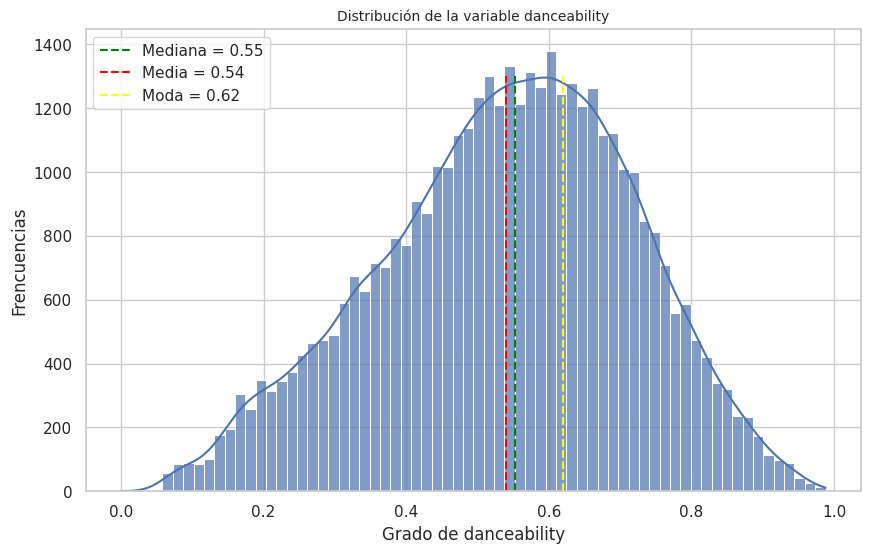

In [13]:
media_dance = all_songs['danceability'].mean()
mediana_dance = all_songs['danceability'].median()
moda_dance = all_songs['danceability'].mode()[0]

sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))


plt.title('Distribución de la variable danceability', fontsize = 10)
plt.xlabel('Grado de danceability')
plt.ylabel('Frencuencias')
sns.histplot(all_songs.danceability, kde = True, bins = 68, alpha = 0.7) #asignando el histograma

plt.vlines(all_songs.danceability.median(),0, 1300, color = 'green', linestyle = '--', label=f'Mediana = {mediana_dance:.2f}')
plt.vlines(all_songs.danceability.mean(),0, 1300, color = 'red', linestyle = '--', label=f'Media = {media_dance:.2f}')
plt.vlines(all_songs.danceability.mode(),0, 1300, color = 'yellow', linestyle = '--', label=f'Moda = {moda_dance:.2f}')

plt.legend(loc = 'upper left')
plt.show()

El gráfico muestra una asimetría negativa, o hacia la izquierda, por la media ser menor tanto a la mediana como a la moda. Se establece que el valor promedio de danceability es 0.54, su valor central es 0.55 y que las canciones tienen en su mayoría un nivel de 0.62 de danceability. A continuación, se presenta una visualización categórica de su distribución divida entre baja, intermedia y alta estableciendo el siguiente criterio: 

* *Baja* si cae por debajo de los 0.3,
* *intermedia* si es superior a 0.3 pero inferior a 0.6 y
* *alta* si supera los 0.6

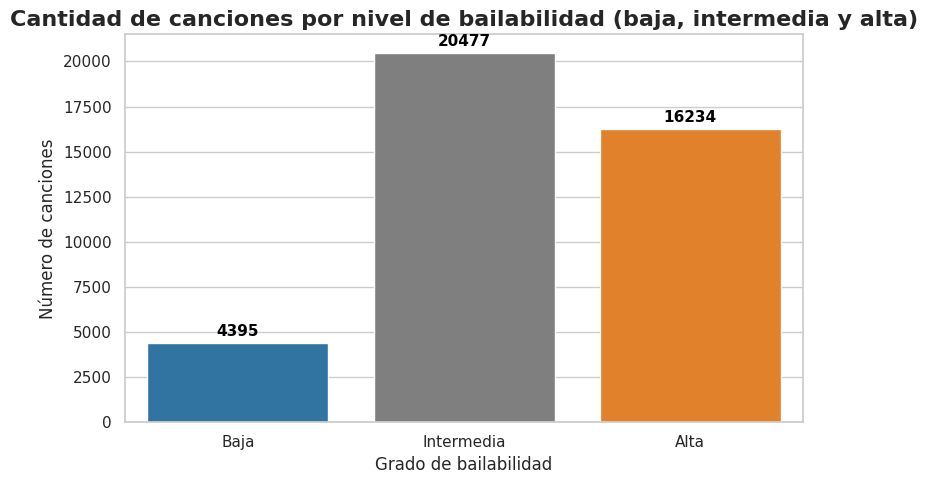

In [14]:
# 1) Variable categórica con orden
danceability_change = all_songs['danceability'].apply(
    lambda v: 'Baja' if v < 0.3 else ('Intermedia' if v <= 0.6 else 'Alta')
)
danceability_change = pd.Categorical(
    danceability_change, categories=['Baja', 'Intermedia', 'Alta'], ordered=True
)

# 2) Colores
palette = {'Baja': "#1f77b4", 'Intermedia': "#7f7f7f", 'Alta': "#ff7f0e"}

# 3) Gráfico 
plt.figure(figsize=(8,5))
graph = sns.countplot(
    x=danceability_change,
    hue=danceability_change,          
    order=['Baja','Intermedia','Alta'],
    hue_order=['Baja','Intermedia','Alta'],
    palette=palette,
    legend=False
)

plt.title('Cantidad de canciones por nivel de bailabilidad (baja, intermedia y alta)',
          fontsize=16, weight='bold')
plt.xlabel('Grado de bailabilidad', fontsize=12)
plt.ylabel('Número de canciones', fontsize=12)

# Etiquetas con conteos
for p in graph.patches:
    graph.annotate(f'{int(p.get_height())}',
                   (p.get_x() + p.get_width()/2., p.get_height()),
                   ha='center', va='baseline', fontsize=11, color='black',
                   weight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()


Con el gráfico de barras podemos identificar la cantidad de canciones divididas por su nivel de danceability (baja/ intermedio / alta).

Si la danceability es menor a 0.3 se considera baja, si supera el 0.3 pero es menor al 0.6 es intermedia y todo aquel valor que supere 0.6 es alto.

Se puede ver que hay una cantidad mayor de canciones con bailabilidad intermedia en todo el dataset. 


## Histograma de energy

A continuación se muestra la distribución de la variable energy en conjunto con sus medidas de tendencia central: 

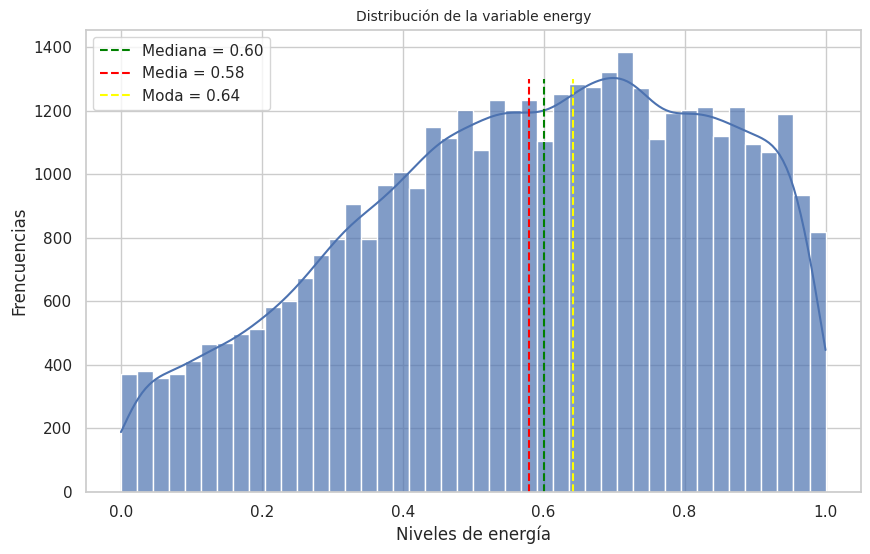

In [15]:
media_energy = all_songs['energy'].mean()
mediana_energy = all_songs['energy'].median()
moda_energy = all_songs['energy'].mode()[0]

sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))


plt.title('Distribución de la variable energy', fontsize = 10)
plt.xlabel('Niveles de energía')
plt.ylabel('Frencuencias')
sns.histplot(all_songs.energy, kde = True, bins = 44, alpha = 0.7) #asignando el histograma

plt.vlines(all_songs.energy.median(),0, 1300, color = 'green', linestyle = '--', label=f'Mediana = {mediana_energy:.2f}')
plt.vlines(all_songs.energy.mean(),0, 1300, color = 'red', linestyle = '--', label=f'Media = {media_energy:.2f}')
plt.vlines(all_songs.energy.mode(),0, 1300, color = 'yellow', linestyle = '--', label=f'Moda = {moda_energy:.2f}')

plt.legend(loc = 'upper left')
plt.show()

El gráfico muestra una asimetría negativa, o hacia la izquierda, por la media ser menor tanto a la mediana como a la moda. Se establece que el valor promedio de energy es 0.58, su valor central es 0.60 y que las canciones tienen en su mayoría un nivel de 0.64 de energy. A continuación, se presenta una visualización categórica de su distribución divida entre baja, intermedia y alta estableciendo el siguiente criterio: 

* *Baja* si cae por debajo de los 0.3,
* *intermedia* si es superior a 0.3 pero inferior a 0.6 y
* *alta* si supera los 0.6

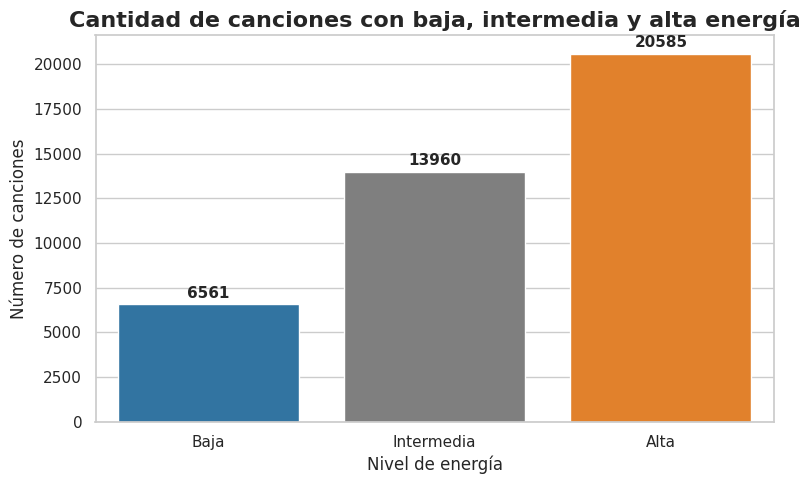

In [16]:
energy_change = all_songs['energy'].apply(
    lambda v: 'Baja' if v < 0.3 else ('Intermedia' if v <= 0.6 else 'Alta')
)
energy_change = pd.Categorical(energy_change,
                               categories=['Baja','Intermedia','Alta'],
                               ordered=True)


palette = {'Baja': "#1f77b4", 'Intermedia': "#7f7f7f", 'Alta': "#ff7f0e"}

 
plt.figure(figsize=(8,5))
ax = sns.countplot(
    x=energy_change,
    hue=energy_change,                 
    order=['Baja','Intermedia','Alta'],
    hue_order=['Baja','Intermedia','Alta'],
    palette=palette,
    legend=False                       
)

plt.title('Cantidad de canciones con baja, intermedia y alta energía',
          fontsize=16, weight='bold')
plt.xlabel('Nivel de energía', fontsize=12)
plt.ylabel('Número de canciones', fontsize=12)


for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='baseline', fontsize=11, weight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

Con el gráfico de barras podemos identificar la cantidad de canciones divididas por su nivel de energia (baja/ intermedio / alta).

Si el energy es menor a 0.3 se considera baja, si supera el 0.3 pero es menor al 0.6 es intermedia y todo aquel valor que supere 0.6 es alto.

Se puede ver que hay una cantidad mayor de canciones con energia alta en todo el dataset.

## Histograma de valence

A continuación se muestra la distribución de la variable valence en conjunto con sus medidas de tendencia central: 

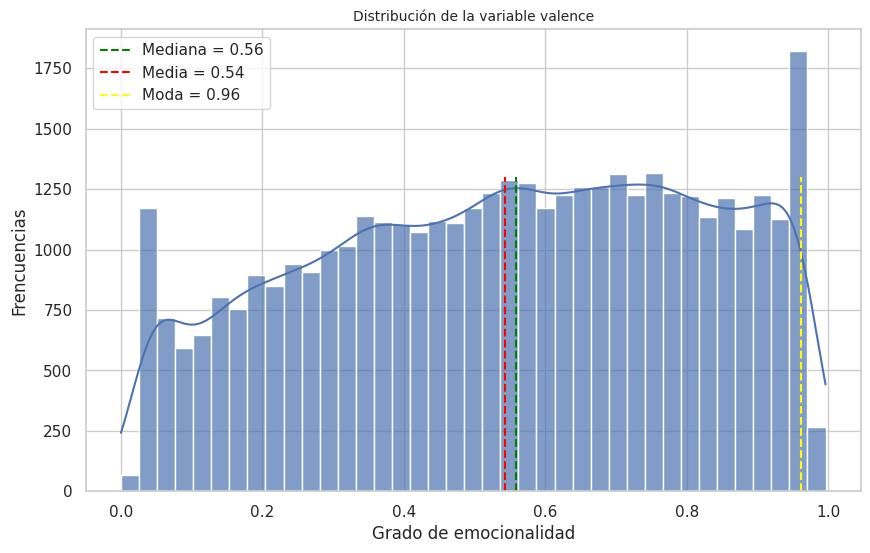

In [17]:
media_valence = all_songs['valence'].mean()
mediana_valence = all_songs['valence'].median()
moda_valence = all_songs['valence'].mode()[0]

sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))


plt.title('Distribución de la variable valence', fontsize = 10)
plt.xlabel('Grado de emocionalidad')
plt.ylabel('Frencuencias')
sns.histplot(all_songs.valence, kde = True, bins = 39, alpha = 0.7) #asignando el histograma

plt.vlines(all_songs.valence.median(),0, 1300, color = 'green', linestyle = '--', label=f'Mediana = {mediana_valence:.2f}')
plt.vlines(all_songs.valence.mean(),0, 1300, color = 'red', linestyle = '--', label=f'Media = {media_valence:.2f}')
plt.vlines(all_songs.valence.mode(),0, 1300, color = 'yellow', linestyle = '--', label=f'Moda = {moda_valence:.2f}')

plt.legend(loc = 'upper left')
plt.show()

El gráfico muestra una asimetría negativa, o hacia la izquierda, por la media ser menor tanto a la mediana y a la moda. Se establece que el valor promedio de valence es 0.54, su valor central es 0.56 y que las canciones tienen en su mayoría un nivel de 0.96 de valence. Dada su distribución platicúrtica, a continuación buscaremos de asignar a las distintas observaciones a categorías para buscar de entender dónde se encuentra su mayor nivel de concentración. Se utilizará el siguiente criterio de clasificación: 

* Si el valor de valence es menor a 0.3, se le considera como *triste*,
* Si el valor de valence es mayor a 0.3 pero menor a 0.6 se le considera como *neutral*,
* Si el valor de valence es mayor a 0.6, entonces se le considera como *feliz*.

Se utiliza un countplot para visualizar dicha distribución categórica.

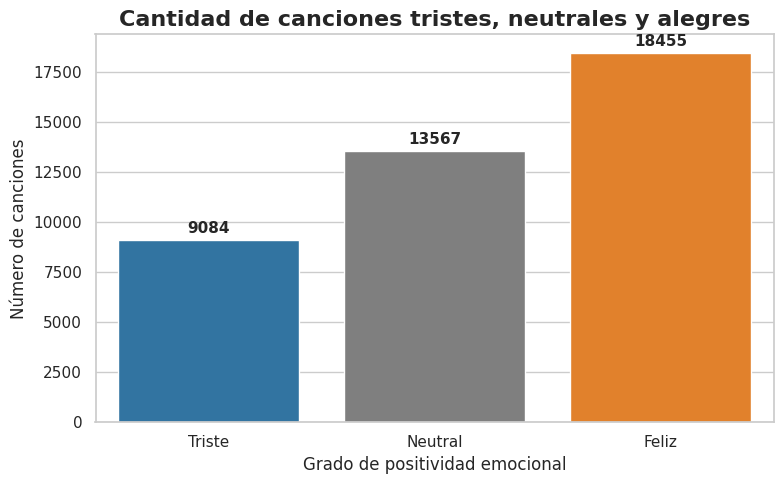

In [18]:
valence_change = all_songs['valence'].apply(
    lambda v: 'Triste' if v < 0.3 else ('Neutral' if v <= 0.6 else 'Feliz')
)
valence_change = pd.Categorical(valence_change,
                                categories=['Triste','Neutral','Feliz'],
                                ordered=True)


palette = {'Triste': "#1f77b4", 'Neutral': "#7f7f7f", 'Feliz': "#ff7f0e"}


plt.figure(figsize=(8,5))
ax = sns.countplot(
    x=valence_change,
    hue=valence_change,                 
    order=['Triste','Neutral','Feliz'],
    hue_order=['Triste','Neutral','Feliz'],
    palette=palette,
    legend=False
)

plt.title('Cantidad de canciones tristes, neutrales y alegres', fontsize=16, weight='bold')
plt.xlabel('Grado de positividad emocional', fontsize=12)
plt.ylabel('Número de canciones', fontsize=12)


for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='baseline', fontsize=11, weight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

A través de esta categorización, es más visible en dónde se encuentran concentrados los datos. En este caso, vemos que existen 18,445 canciones alegres/felices mientras que existen solo 9,804 canciones tristes. Esto explica el valor de la moda de 0.96, la cual muestra la mayor frecuencia de canciones de felicidad. La media y la mediana se ubican dentro de la categoría neutral por ser menor a 0.6. 

### Finalmente, a través del uso de boxplots, comparamos las distribuciones de las tres variables en paralelo para medir su niveles de varianza entre sus valores, al igual que la existencia de valores extremos entre cualquiera de ellos.

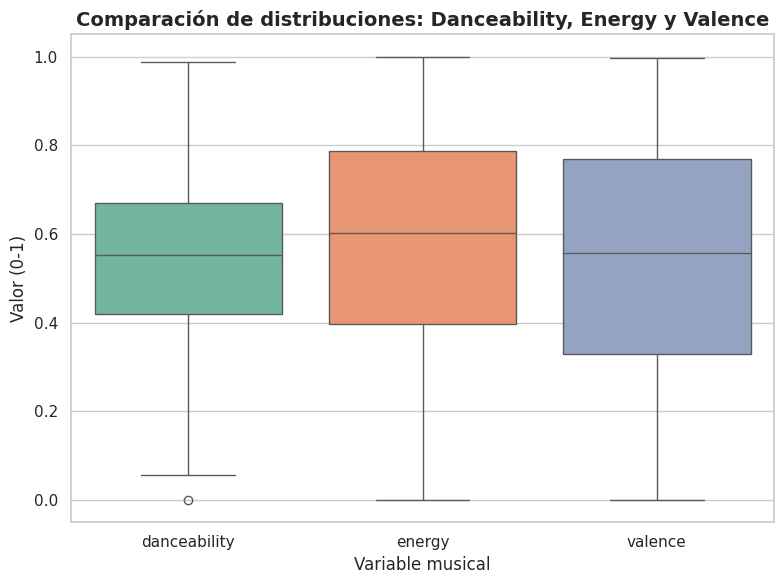

In [19]:
subset = all_songs[['danceability', 'energy', 'valence']]
df_long = subset.melt(var_name='Variable', value_name='Valor')


orden = ['danceability', 'energy', 'valence']
df_long['Variable'] = pd.Categorical(df_long['Variable'], categories=orden, ordered=True)
palette = {'danceability': '#66c2a5', 'energy': '#fc8d62', 'valence': '#8da0cb'}  # Set2

plt.figure(figsize=(8,6))
ax = sns.boxplot(
    data=df_long,
    x='Variable',
    y='Valor',
    hue='Variable',          
    hue_order=orden,
    palette=palette,
    dodge=False,             
    legend=False             
)
plt.title("Comparación de distribuciones: Danceability, Energy y Valence", fontsize=14, weight='bold')
plt.xlabel("Variable musical", fontsize=12)
plt.ylabel("Valor (0-1)", fontsize=12)
plt.tight_layout()
plt.show()

En esta comparación de distribuciones, logramos visualizar como danceability tiene una menor dispersión que energy y valence, lo cual indica que las canciones tienden a mantener un nivel de bailabilidad más homogéneo en relación a estas otras dos variables. El valor extremo en danceability indica que dicha canción en específico tiene un nivel bajo de bailabilidad, lo cual puede relacionarse con bajos niveles tanto de energía como emocional. El tamaño de la caja de valence indica la variabilidad entre el tipo de emocionalidad que pueden traer las canciones, siendo esta variabilidad un poco mayor a la encontrada en los niveles de energia y bailabilidad. En cambio, vemos que la concentración de los valores de energy se mantiene bajo los niveles intermedios-altos. Esto sugiere que, aunque la emoción de las canciones puede variar bastante, las producciones musicales tienden a mantener un estándar de energía constante, posiblemente asociado a lo que resulta atractivo para un público amplio.



## Adicional: medidas de tendencia central para demás variables




### Loudness: volumen de las canciones

In [21]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
all_songs['loudness_scaled'] = scaler.fit_transform(all_songs[['loudness']])


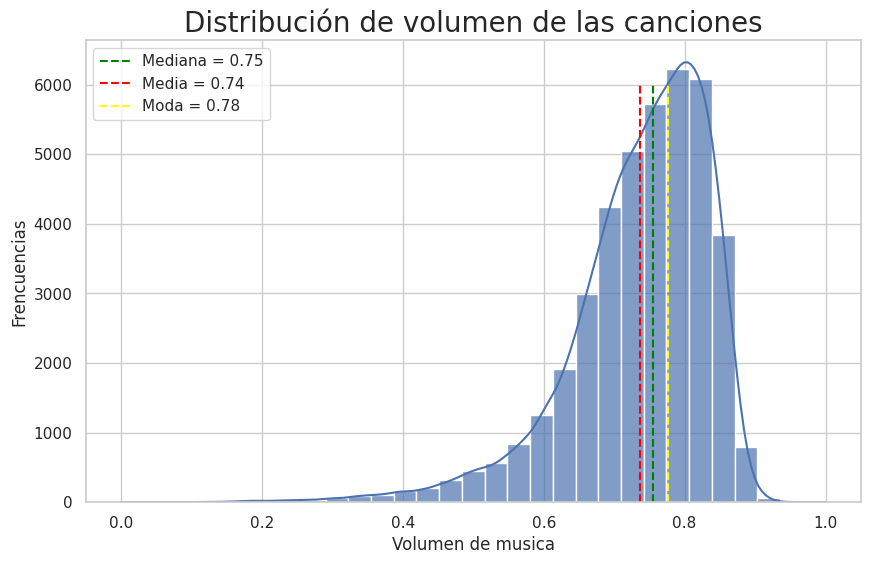

In [22]:
media_loudness = all_songs['loudness_scaled'].mean()
mediana_loudness = all_songs['loudness_scaled'].median()
moda_loudness = all_songs['loudness_scaled'].mode()[0]

sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))


plt.title('Distribución de volumen de las canciones', fontsize = 20)
plt.xlabel('Volumen de musica')
plt.ylabel('Frencuencias')
sns.histplot(all_songs.loudness_scaled, kde = True, bins = 31, alpha = 0.7) #asignando el histograma

plt.vlines(all_songs.loudness_scaled.median(),0, 6000, color = 'green', linestyle = '--', label=f'Mediana = {mediana_loudness:.2f}')
plt.vlines(all_songs.loudness_scaled.mean(),0, 6000, color = 'red', linestyle = '--', label=f'Media = {media_loudness:.2f}')
plt.vlines(all_songs.loudness_scaled.mode(),0, 6000, color = 'yellow', linestyle = '--', label=f'Moda = {moda_loudness:.2f}')

plt.legend(loc = 'upper left')
plt.show()

Dado a que el ruido esta expresado en decibelios (dB), por lo cual esta expuesto a la existencia de números negativos, establecimos una escala de menor a mayor para analizar dicha distribución, siendo 0 la cancion más silenciosa de todo el dataset y 1 la canción más fuerte del dataset.

En este caso tenemos una asimetria negativa ya que la media es menor a su mediana y modo. Logramos ver que en promedio el volumen musical es de 0.74. 
Su valor central es de 0.75.
Las canciones tienden a estar en un valor de 0.78. 

### Tempo: velocidad estimada en beats por minuto

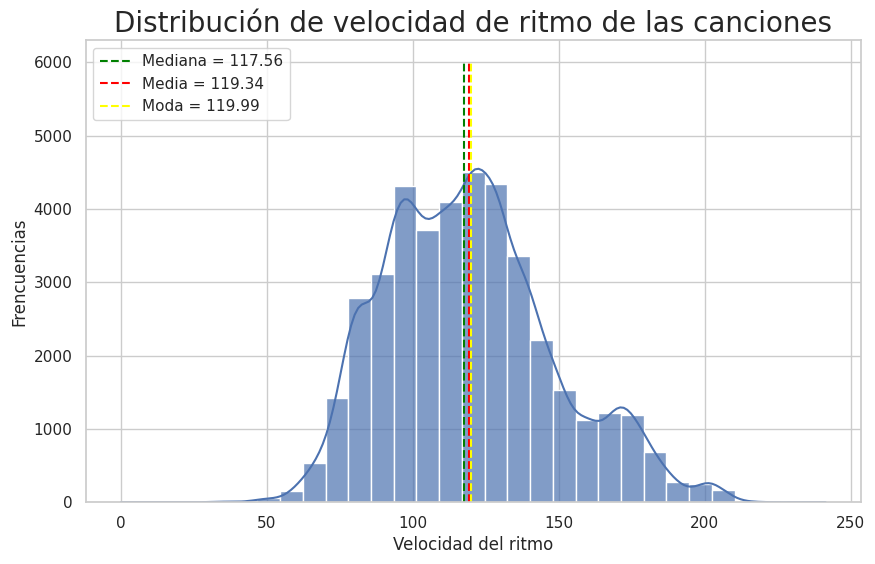

In [23]:
media_tempo = all_songs['tempo'].mean()
mediana_tempo = all_songs['tempo'].median()
moda_tempo = all_songs['tempo'].mode()[0]

sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))


plt.title('Distribución de velocidad de ritmo de las canciones', fontsize = 20)
plt.xlabel('Velocidad del ritmo')
plt.ylabel('Frencuencias')
sns.histplot(all_songs.tempo, kde = True, bins = 31, alpha = 0.7) #asignando el histograma

plt.vlines(all_songs.tempo.median(),0, 6000, color = 'green', linestyle = '--', label=f'Mediana = {mediana_tempo:.2f}')
plt.vlines(all_songs.tempo.mean(),0, 6000, color = 'red', linestyle = '--', label=f'Media = {media_tempo:.2f}')
plt.vlines(all_songs.tempo.mode(),0, 6000, color = 'yellow', linestyle = '--', label=f'Moda = {moda_tempo:.2f}')

plt.legend(loc = 'upper left')
plt.show()

En este caso tenemos una asimetria negativa ya que la moda es mayor a la media pese a que la mediana sea menor. Logramos ver que en promedio el ritmo musical es de 119.34.
Su valor central es de 117.56. 
Las canciones tienden a estar en un valor de 119.99.

# Relación de features con el target

## Violin plot instrumentalness por clase

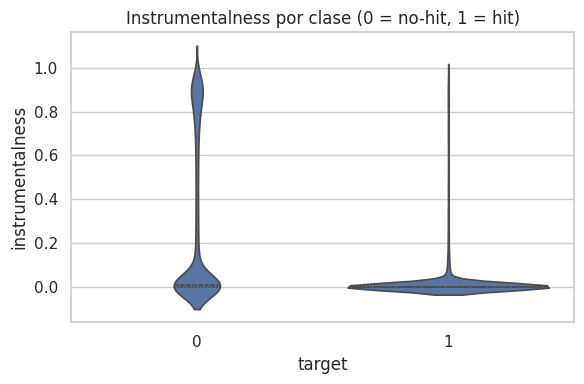

In [26]:
plt.figure(figsize=(6,4))
sns.violinplot(data=df, x="target", y="instrumentalness", inner="quartile")
plt.title("Instrumentalness por clase (0 = no-hit, 1 = hit)")
plt.tight_layout()
plt.show()

El violin plot muestra cómo se distribuye la variable instrumentalness en cada clase del label: a la izquierda, las canciones que no fueron hit (0) y, a la derecha, las que sí lo fueron (1). La amplitud del violín en cada altura representa la densidad de observaciones (más ancho = más frecuente) y las marcas internas indican los cuartiles. En la clase de hits la masa de la distribución aparece casi completamente pegada a 0, con cuartiles muy cercanos entre sí; esto sugiere que, cuando una canción es exitosa, la componente instrumental pura es mínima y predomina la voz. En cambio, en la clase de no-hits la distribución es mucho más ancha y presenta una cola hacia valores altos de instrumentalness, lo que indica que allí hay muchas más piezas instrumentales o con fuerte predominio de lo instrumental. El solapamiento entre ambas clases es reducido a partir de valores moderados (≈0,05–0,10): por encima de ese rango, casi todo pertenece a no-hits. En conjunto, el gráfico respalda que instrumentalness es un feature fuerte y con relación negativa con el éxito (a menor instrumentalness, mayor probabilidad de hit).

## Violin plot danceability por clase

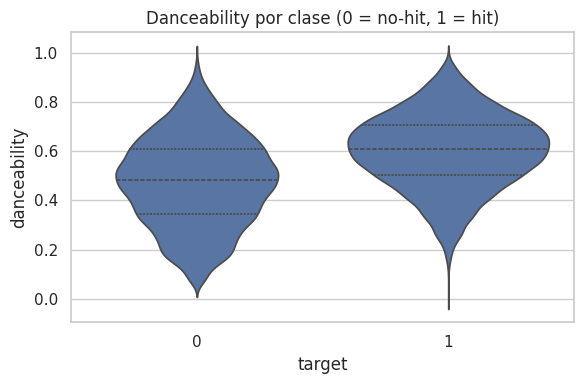

In [27]:
plt.figure(figsize=(6,4))
sns.violinplot(data=df, x="target", y="danceability", inner="quartile")
plt.title("Danceability por clase (0 = no-hit, 1 = hit)")
plt.tight_layout()
plt.show()

El violin plot muestra la distribución de danceability en cada clase del label, de la misma manera que el gráfico anterior. 
Se observa un desplazamiento claro hacia valores más altos de danceability en la clase hit: la masa principal se concentra alrededor de 0,55–0,70 y la mediana está por encima de la de los no-hits. En no-hits, el centro de la distribución queda más bajo (alrededor de 0,40–0,55), con mayor presencia de valores en la franja inferior. Aunque existe solapamiento entre ambas clases (hay canciones poco y muy bailables en ambos grupos), el violín de hits está corrído arriba, lo que indica que mayor bailabilidad se asocia con mayor probabilidad de éxito.
En conjunto, la figura sugiere que danceability es un predictor positivo del éxito, con separación moderada (no perfecta), coherente con que la media en hits sea mayor que en no-hits.

## Violin plot loudness por clase

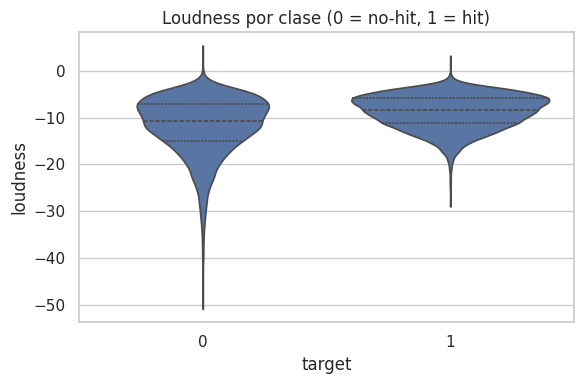

In [28]:
plt.figure(figsize=(6,4))
sns.violinplot(data=df, x="target", y="loudness", inner="quartile")
plt.title("Loudness por clase (0 = no-hit, 1 = hit)")
plt.tight_layout()
plt.show()

Este violin plot compara el nivel sonoro (en dB, valores menos negativos = más fuerte) entre no-hits (0) y hits (1). En la clase hit la distribución está desplazada hacia arriba (más cerca de 0 dB): la mediana es mayor (menos negativa) y el rango intercuartílico se sitúa en un tramo más alto que el de los no-hits. En no-hits aparece además una cola más pronunciada hacia valores muy bajos (más negativos), señal de piezas notablemente más “calladas”. En términos prácticos: las canciones exitosas están masterizadas más fuerte y con menor proporción de niveles muy bajos. Hay solapamiento entre grupos, pero el desplazamiento central es claro, lo que respalda que loudness sea un predictor positivo del éxito.

## Violin plot valence por clase

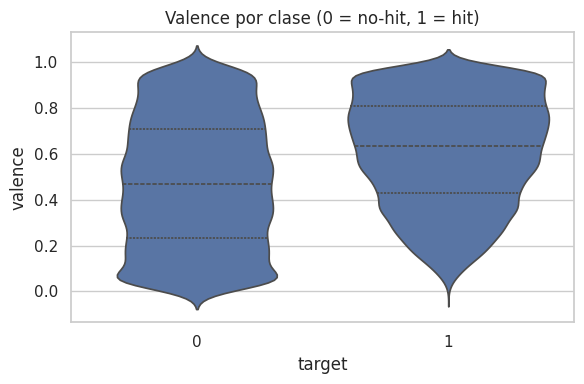

In [29]:
plt.figure(figsize=(6,4))
sns.violinplot(data=df, x="target", y="valence", inner="quartile")
plt.title("Valence por clase (0 = no-hit, 1 = hit)")
plt.tight_layout()
plt.show()

Este violin plot compara el “tono emocional” (0 = triste/oscuro, 1 = alegre/positivo) entre no-hits (0) y hits (1). En los hits la distribución está desplazada hacia arriba: la mediana y todo el rango intercuartílico se ubican en valores más altos, con mucha densidad sostenida en ~0,60–0,80. En los no-hits se observa mayor masa en la banda baja–media (≈0,20–0,55) y menor presencia continua en la zona alta, lo que indica un clima afectivo menos positivo. Aunque existe solapamiento entre clases (hay hits con valence medio y no-hits con valence alto), el corrimiento central es claro y sugiere una asociación positiva y aproximadamente monótona entre valence y probabilidad de éxito.

## Violin plot para tempo, liveness, chorus_hit, sections y duration_ms por clase

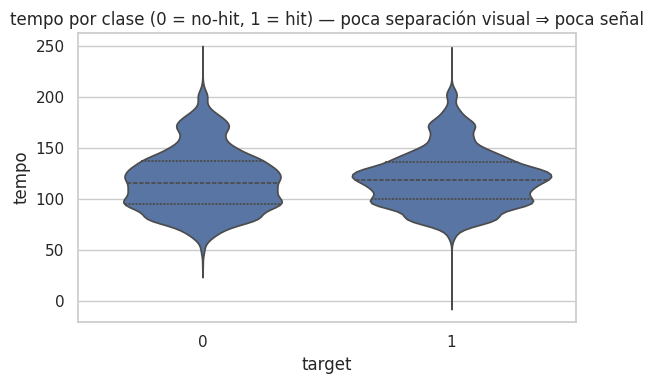

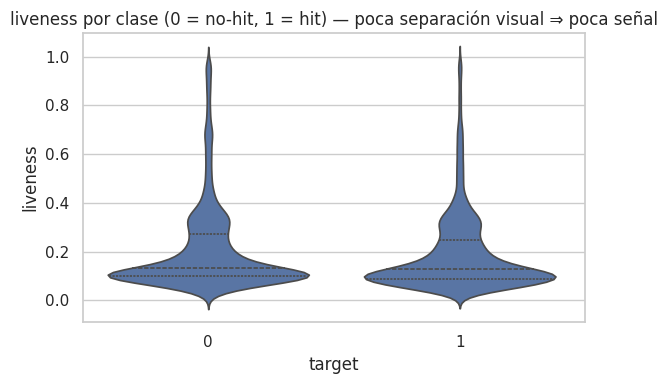

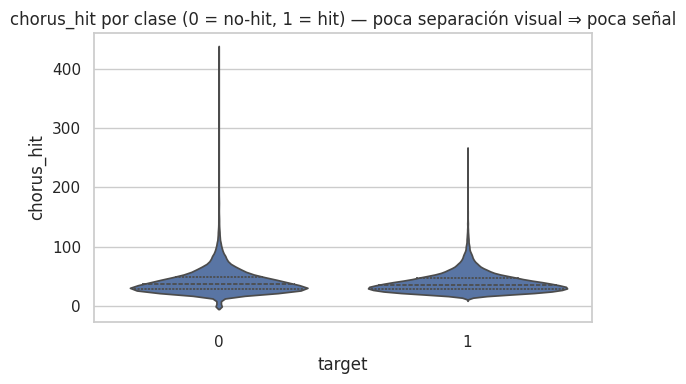

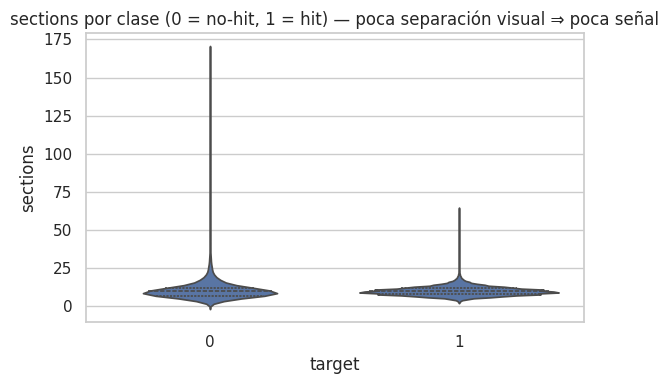

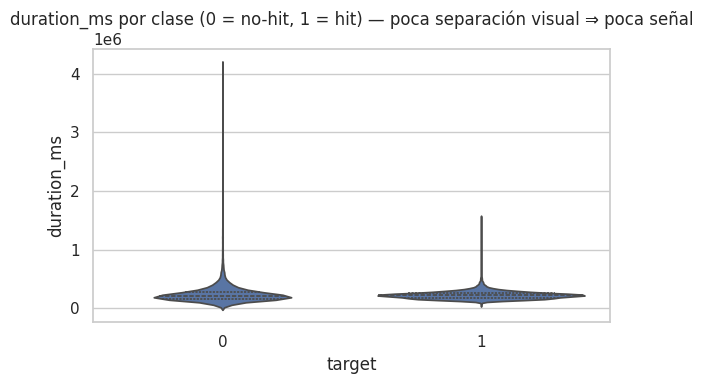

In [32]:
for col in low_feats:
    plt.figure(figsize=(6,4))
    sns.violinplot(data=df, x="target", y=col, inner="quartile")
    plt.title(f"{col} por clase (0 = no-hit, 1 = hit) — poca separación visual ⇒ poca señal")
    plt.tight_layout()
    plt.show()

Los cinco violin plots comparan, para cada feature, la distribución en no-hits (0) y hits (1); la anchura del violín refleja la densidad y las líneas punteadas marcan Q1–mediana–Q3. 

* tempo. Ambos violin plots tienen el grueso de la masa en un rango idéntico (~95–135 BPM) y los cuartiles se superponen. Hay picos locales parecidos y ninguna franja del eje donde una clase domine claramente. Conclusión: ordenar por tempo no discrimina.

* liveness. Distribuciones fuertemente asimétricas y apiladas en valores bajos (~0,05–0,20) para ambos grupos, con colas esporádicas hacia valores altos. Las medianas son casi iguales y el IQR (rango intercuartil) coincide; la señal univariada es muy débil.

* chorus_hit. Gran parte de los estribillos aparece en la misma ventana temporal para hits y no-hits (alrededor de las primeras decenas de segundos). Se percibe un desplazamiento leve de los hits hacia valores algo menores (estribillo ligeramente más temprano), pero el solapamiento domina todo el soporte.

* sections. Los hits parecen tener una distribución algo más estrecha y centrada en menos secciones, mientras que los no-hits exhiben mayor dispersión y alguna cola extrema. Aun así, medianas e IQR son muy próximos; la separación visual es marginal.

* duration_ms. Los hits muestran una duración promedio algo menor y menos extremos; los no-hits presentan colas largas (piezas muy extensas). Sin embargo, en el rango central (≈2,5–4 min) las distribuciones se solapan fuertemente, por lo que la diferencia media no se traduce en una buena separación global.

En síntesis, estas figuras explican por qué, usadas en aislamiento, estas variables ordenan casi como el azar: las distribuciones por clase se parecen demasiado en todo el rango.

## Gráficos de densidad por clase para tempo, liveness, chorus_hit, sections y duration_ms

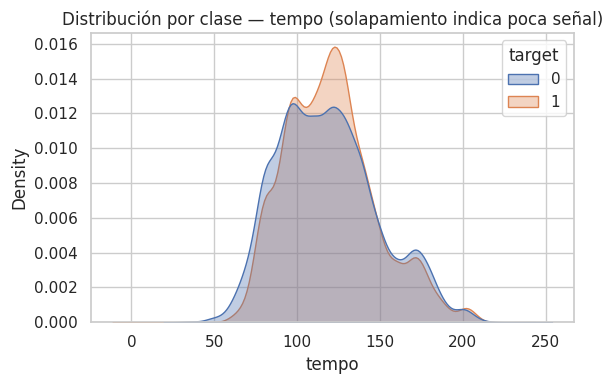

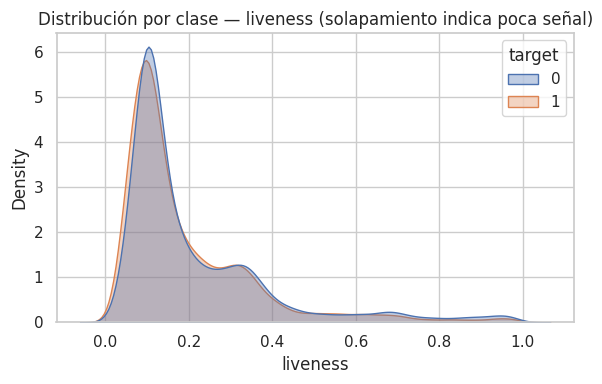

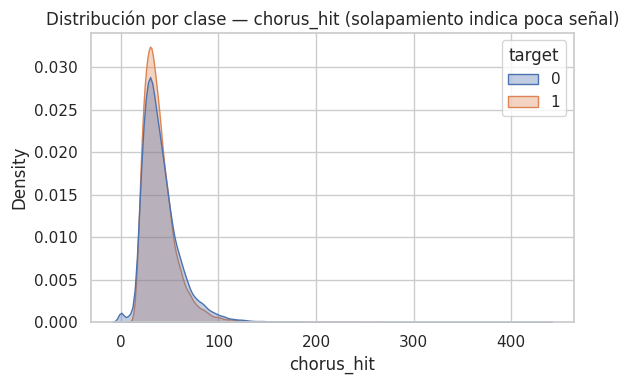

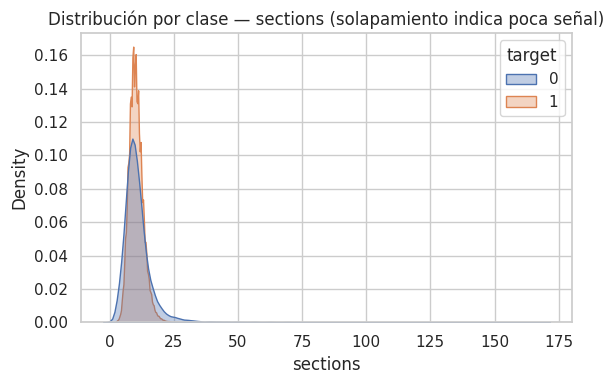

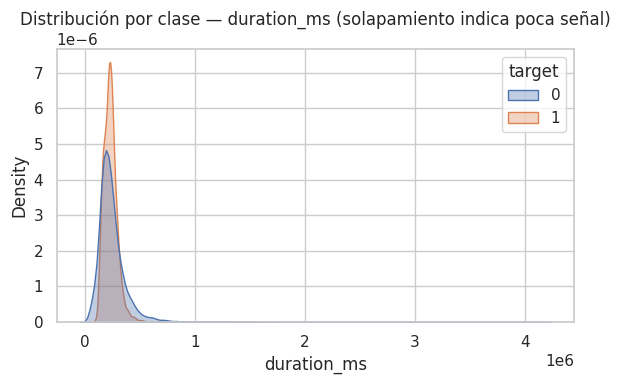

In [30]:
low_feats = ["tempo","liveness","chorus_hit","sections","duration_ms"]  # cambia según tus columnas
for col in low_feats:
    plt.figure(figsize=(6,4))
    sns.kdeplot(data=df, x=col, hue="target", common_norm=False, fill=True, alpha=0.35)
    plt.title(f"Distribución por clase — {col} (solapamiento indica poca señal)")
    plt.tight_layout()
    plt.show()

Los cinco gráficos de densidad (KDE) comparan la distribución de cada variable entre no-hits (0) y hits (1). En todos los casos se aprecia un solapamiento muy amplio entre las curvas azul y naranja, lo que visualmente respalda que estas variables, por sí solas, tienen poca capacidad de separar las clases.

En tempo, ambas clases concentran su masa en el mismo rango (aprox. 90–140 BPM) con picos muy próximos; cualquier diferencia local es mínima, por lo que “ordenar por tempo” no discrimina. 

En liveness ocurre algo similar: ambas distribuciones son fuertemente asimétricas y se apilan en valores bajos (~0,05–0,20), prácticamente indistinguibles salvo variaciones sutiles; la señal univariada es, por tanto, muy débil. 

En chorus_hit (momento del primer estribillo) las dos curvas son casi calco con un leve corrimiento de los hits hacia valores ligeramente menores (estribillo algo más temprano), pero insuficiente para una separación efectiva; el solapamiento domina el soporte. 

En sections (cantidad de secciones) también se observa una superposición amplia: los hits muestran una distribución algo más estrecha y apenas desplazada a la izquierda (menos secciones en promedio), pero la mayor parte de la masa coincide con la de los no-hits. 

Por último, duration_ms presenta colas largas y, aunque los hits son algo más cortos en promedio, la mayor parte de ambas distribuciones coincide en el rango central (≈ 2,5–4 min), de nuevo con separación práctica muy limitada.


# Correlación entre las variables

Bajo el siguiente análisis buscaremos de entender el cómo interactuan entre sí las distintas variables del dataset.

El siguiente gráfico muestra cómo varían las principales características musicales entre canciones populares y no populares, destacando cuáles tienen mayor influencia en la popularidad.

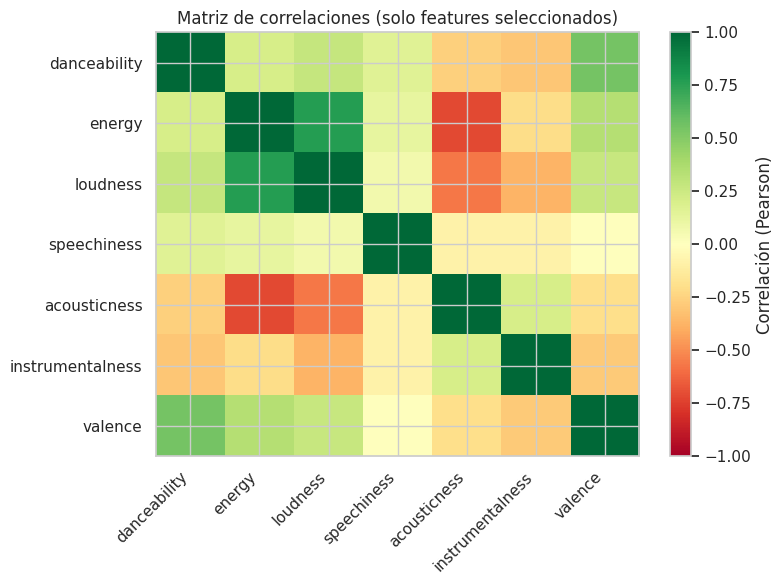

In [33]:
df = all_songs  

wanted = ["danceability","energy","loudness","speechiness",
          "acousticness","instrumentalness","valence"]
if "valence" not in df.columns and "valance" in df.columns:
    df = df.rename(columns={"valance": "valence"})

features_hm = [c for c in wanted if c in df.columns]
missing = [c for c in wanted if c not in features_hm]
if missing:
    print("Aviso: faltan columnas en el dataframe:", missing)

corr = df[features_hm].corr()
C = corr.values

fig, ax = plt.subplots(figsize=(8,6))
im = ax.imshow(C, vmin=-1, vmax=1, cmap="RdYlGn", aspect="auto")  
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Correlación (Pearson)")

ax.set_xticks(np.arange(len(features_hm))); ax.set_yticks(np.arange(len(features_hm)))
ax.set_xticklabels(features_hm, rotation=45, ha="right"); ax.set_yticklabels(features_hm)

plt.title("Matriz de correlaciones (solo features seleccionados)")
plt.tight_layout()
plt.show()

## Encontramos que las canciones populares son más bailables, energéticas, alegres y suenan más fuerte. 
Ademas son menos habladas, menos acústicas y rara vez instrumentales.

A continuación se presentan cuatro gráficos de densidad que muestran la relación entre distintos atributos de canciones mostrados previamente en la matriz. 
Cada gráfico incluye el coeficiente de correlación (r) para medir la relación lineal entre dos variables.

Entendiendo que:

r cercano a +1 → correlación positiva fuerte (cuando una variable aumenta, la otra también).

r cercano a -1 → correlación negativa fuerte (cuando una variable aumenta, la otra disminuye).

r cercano a 0 → correlación débil o inexistente.

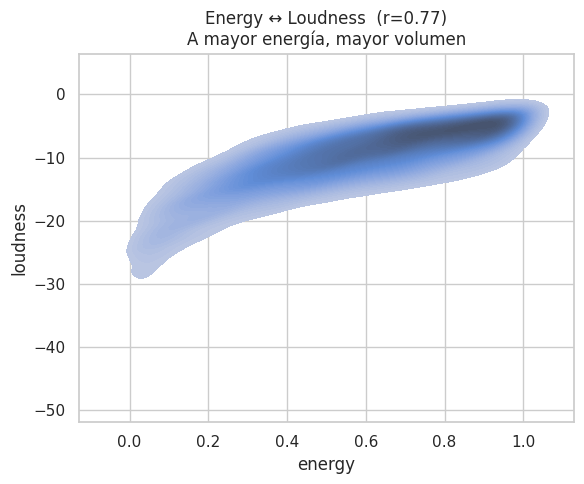

In [34]:
df = all_songs.copy()
tmp = df[["energy","loudness"]].dropna().copy()
if len(tmp) > 100_000:
    tmp = tmp.sample(100_000, random_state=42)

r = tmp["energy"].corr(tmp["loudness"])

plt.figure(figsize=(6,5))
sns.kdeplot(data=tmp, x="energy", y="loudness", fill=True, thresh=0.05, levels=50)
plt.title(f"Energy ↔ Loudness  (r={r:.2f})\nA mayor energía, mayor volumen", fontsize=12)
plt.xlabel("energy"); plt.ylabel("loudness")
plt.tight_layout()
plt.savefig("kde_energy_vs_loudness.png", dpi=200)
plt.show()


La relación entre Energy y Loudness tiene un coeficiente de r=0.77, corresponde a una correlación positiva fuerte. 
Esto significa que, en la mayoría de los casos, a mayor energía percibida en una canción también se incrementa su volumen promedio.

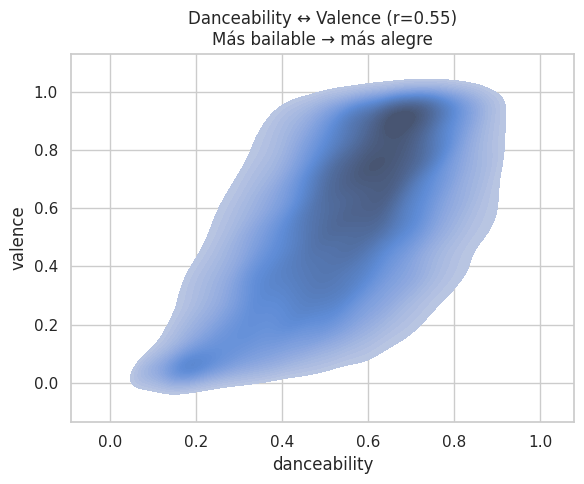

In [35]:
df = all_songs.copy()
tmp = df[["danceability","valence"]].dropna().copy()
if len(tmp) > 100_000:
    tmp = tmp.sample(100_000, random_state=42)
r = tmp["danceability"].corr(tmp["valence"])
plt.figure(figsize=(6,5))
sns.kdeplot(data=tmp, x="danceability", y="valence", fill=True, thresh=0.05,
levels=50)
plt.title(f"Danceability ↔ Valence (r={r:.2f})\nMás bailable → más alegre", fontsize=12)
plt.xlabel("danceability"); plt.ylabel("valence")
plt.tight_layout()
plt.savefig("kde_danceability_vs_valence.png", dpi=200)
plt.show()

La relación entre Danceability y Valence tiene un coeficiente de r=0.55. 
Este valor representa una correlación positiva moderada, lo que indica que las canciones más bailables tienden a transmitir emociones más alegres y positivas. 
Aunque no todas las canciones diseñadas para bailar necesariamente son alegres.

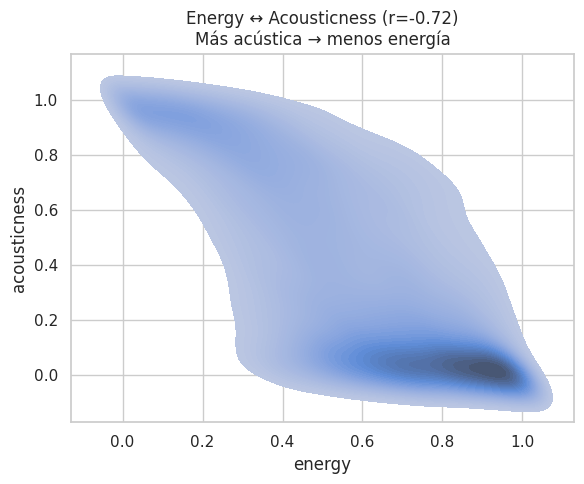

In [36]:
df = all_songs.copy()
tmp = df[["energy","acousticness"]].dropna().copy()
if len(tmp) > 100_000:
    tmp = tmp.sample(100_000, random_state=42)
r = tmp["energy"].corr(tmp["acousticness"])
plt.figure(figsize=(6,5))
sns.kdeplot(data=tmp, x="energy", y="acousticness", fill=True, thresh=0.05,
levels=50)
plt.title(f"Energy ↔ Acousticness (r={r:.2f})\nMás acústica → menos energía", fontsize=12)
plt.xlabel("energy"); plt.ylabel("acousticness")
plt.tight_layout()
plt.savefig("kde_energy_vs_acousticness.png", dpi=200)
plt.show()


La relación entre Energy y Acousticness tiene un coeficiente de r=-0.72, que corresponde a una correlación negativa fuerte. 
Esto significa que, conforme aumenta el carácter acústico de una canción, disminuye de manera consistente su nivel de energía.

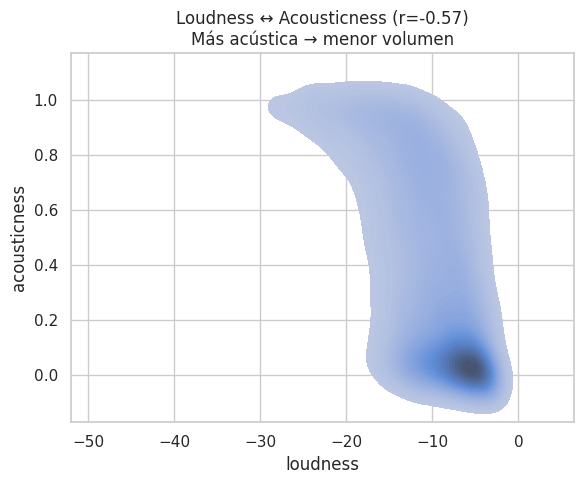

In [37]:
df = all_songs.copy()
tmp = df[["loudness","acousticness"]].dropna().copy()
if len(tmp) > 100_000:
    tmp = tmp.sample(100_000, random_state=42)
r = tmp["loudness"].corr(tmp["acousticness"])
plt.figure(figsize=(6,5))
sns.kdeplot(data=tmp, x="loudness", y="acousticness", fill=True,
thresh=0.05, levels=50)
plt.title(f"Loudness ↔ Acousticness (r={r:.2f})\nMás acústica → menor volumen", fontsize=12)
plt.xlabel("loudness"); plt.ylabel("acousticness")
plt.tight_layout()
plt.savefig("kde_loudness_vs_acousticness.png", dpi=200)
plt.show()

La relación entre Loudness y Acousticness, con un coeficiente de r=-0.57, muestra que la relación inversa es moderada,
las canciones acústicas en general presentan menor loudness.

## Conclusión de la etapa del análisis exploratorio

En esta etapa, a partir del análisis de las relaciones entre el target y las variables en conunto con el analisis de distribucion, identificamos aquellas que presentan mayor incidencia en la clasificación de las canciones como HIT o NO-HIT.
Logrando asi entender las caracteristicas que se relacionan con las canciones mas populares, `instrumentalness`, `danceability`, `loudness`, `valence`, `acousticness`, `energy` y `speechiness`. 

En instrumentalness, los hits presentan valores cercanos a 0, mientras que los no-hits muestran una media más alta (diferencia aproximada de 0.25–0.30), lo que evidencia que las canciones con menor contenido instrumental tienden a ser más exitosas. 

En danceability, la media de los hits se ubica entre 0.60 y 0.70, frente a 0.45–0.55 en los no-hits, con una diferencia de alrededor de 0.12, indicando que la bailabilidad es un factor positivo en la popularidad. 

En loudness, los hits registran valores promedio de –5 dB frente a –9 dB en no-hits (una diferencia de 4 dB), mostrando que las canciones más fuertes o intensas tienden a alcanzar mayor éxito.

En valence, la diferencia entre clases ronda los 0.15–0.20, con hits más concentrados en valores altos (0.60–0.80), lo que sugiere una mayor positividad emocional. 

En energy, los hits promedian entre 0.70 y 0.85, mientras que los no-hits se sitúan en torno a 0.60–0.70, con una diferencia media de 0.10–0.12, indicando que las canciones más enérgicas son preferidas por el público. 

En speechiness, la diferencia es más leve (0.05–0.08), pero los hits muestran mayor presencia de secciones vocales o líricas.

En acousticness presenta una diferencia cercana a 0.10, siendo más alta en los no-hits, lo que confirma que las canciones exitosas tienden a tener una menor componente acústica.

En conjunto, estas variaciones cuantitativas justifican la selección de features, ya que todas presentan diferencias significativas en media o rango intercuartílico entre ambas clases, reflejando una relación directa con las características de las canciones más populares:

Por el contrario, variables como tempo, liveness, sections, chorus_hit y duration_ms fueron descartadas al mostrar diferencias menores a 0.05 y un solapamiento casi total entre las clases, sin aporte discriminante relevante.

## Etapa de Desarrollo y Entrenamiento de los Modelos

### Metodología de resolución

El objetivo del proyecto es construir un modelo de clasificación que prediga si una canción será un **hit (1)** o **no-hit (0)**, a partir de sus características de audio.  

Luego del análisis exploratorio, se identificó que las variables con mayor capacidad predictiva fueron:

`instrumentalness`, `danceability`, `loudness`, `valence`, `acousticness`, `energy` y `speechiness`.

Estas variables se seleccionaron en base a:
- Su **AUC univariado** superior al resto.
- Su **mutual information** no nula.
- Su **relevancia interpretativa** en el perfil musical de los hits (baja instrumentalidad, mayor energía, mayor volumen y tono emocional positivo).

El proceso metodológico seguido es el siguiente:

1. Preparación y limpieza del dataset.  
2. Selección de features relevantes basadas en análisis univariado y correlaciones.  
3. Separación del dataset en entrenamiento y validación (estratificada para conservar proporción de clases).  
4. Entrenamiento de modelos supervisados (Regresión Logística, Random Forest y Gradient Boosting).  
5. Evaluación comparativa según métricas de desempeño (principalmente ROC-AUC).  
6. Interpretación de resultados y matriz de confusión para todos los modelos.

**Justificación de la elección de los modelos**

Para abordar el problema de clasificación binaria —predecir si una canción será un hit o no-hit a partir de sus características musicales— se seleccionaron tres algoritmos representativos de distintas familias de modelos supervisados: Regresión Logística, Random Forest y Gradient Boosting.
La elección responde a la necesidad de comparar enfoques con distintos grados de complejidad, capacidad de modelar relaciones no lineales e interpretabilidad, de acuerdo con los principios de aprendizaje supervisado y el equilibrio entre sesgo y varianza.

La Regresión Logística se incorporó como modelo base de referencia por su simplicidad, rapidez y alta interpretabilidad. Es un modelo lineal que estima la probabilidad de pertenencia a una clase en función de una combinación lineal de las variables predictoras. Su estructura permite comprender fácilmente el efecto de cada característica (por ejemplo, cómo un incremento en danceability o valence afecta la probabilidad de éxito de una canción).
Además, al ser un modelo de baja varianza y alta estabilidad, permite establecer un punto de partida desde el cual comparar la ganancia real que se obtiene al emplear modelos más complejos. Su inclusión garantiza una perspectiva interpretativa del fenómeno y proporciona una base teórica sólida dentro del análisis.

El Random Forest, en cambio, representa un modelo no lineal y de mayor complejidad que la regresión logística. Se trata de un ensamble de múltiples árboles de decisión entrenados sobre subconjuntos aleatorios de los datos y de las variables, lo que permite capturar interacciones complejas entre las características musicales y el resultado final.
Su mecanismo de bagging (promediar las predicciones de múltiples árboles) le otorga una gran robustez frente al sobreajuste, manteniendo un equilibrio adecuado entre sesgo y varianza. Este modelo resulta especialmente útil cuando las relaciones entre variables no siguen patrones estrictamente lineales, como suele ocurrir con variables como energy, loudness o acousticness, que interactúan entre sí para definir el perfil sonoro de un hit.

Finalmente, el Gradient Boosting se incorporó como modelo de máxima capacidad predictiva dentro del conjunto seleccionado. Al igual que el Random Forest, pertenece a la familia de ensambles de árboles, pero se diferencia por su enfoque secuencial: cada nuevo árbol se entrena corrigiendo los errores cometidos por los anteriores.
Este método permite ajustar el modelo de manera más fina, optimizando el sesgo y la varianza a través de técnicas de regularización, tasa de aprendizaje y profundidad de los árboles. Su desempeño suele superar al de otros clasificadores en términos de métricas como ROC-AUC y F1-score, especialmente en contextos donde las relaciones entre las variables son altamente no lineales o donde pequeños matices en los datos pueden marcar diferencias relevantes.

La combinación de estos tres modelos —Regresión Logística, Random Forest y Gradient Boosting— permite realizar una comparación integral que cubre todo el espectro de complejidad del aprendizaje supervisado.
La Regresión Logística actúa como benchmark lineal e interpretable, mientras que Random Forest y Gradient Boosting aportan modelos no lineales de alta capacidad predictiva, ofreciendo distintas perspectivas sobre la estructura de los datos y la naturaleza del problema.
Esta selección equilibrada posibilita analizar el impacto de la complejidad del modelo en el rendimiento predictivo y en la interpretabilidad, proporcionando una visión completa sobre cuál de los enfoques resulta más adecuado según los objetivos del análisis y los recursos disponibles.


### Separación en datos de entrenamiento y validación

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


features = ['instrumentalness', 'danceability', 'loudness',
            'valence', 'acousticness', 'energy', 'speechiness']

X = df[features].copy()
y = df['target'].astype(int)


X = X.fillna(X.median(numeric_only=True))


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f"Tamaño de entrenamiento: {X_train.shape}")
print(f"Tamaño de validación: {X_test.shape}")
print(f"Proporción de clase positiva (train): {y_train.mean():.3f}")
print(f"Proporción de clase positiva (test): {y_test.mean():.3f}")


Tamaño de entrenamiento: (28774, 7)
Tamaño de validación: (12332, 7)
Proporción de clase positiva (train): 0.500
Proporción de clase positiva (test): 0.500


### Elección de la métrica

Dado que el objetivo del modelo es clasificar correctamente si una canción será un hit (1) o no-hit (0), y que las clases se encuentran balanceadas (50%-50%), se seleccionaron métricas que permitan evaluar tanto la capacidad de discriminación global como el rendimiento puntual de clasificación.

**1. ROC-AUC (Receiver Operating Characteristic - Area Under Curve)**  
Será la métrica principal, ya que mide la capacidad del modelo para distinguir entre ambas clases a lo largo de todos los umbrales posibles.  
Un valor de **AUC cercano a 1** indica una excelente capacidad discriminante, mientras que un **AUC de 0.5** refleja un desempeño equivalente al azar.  
Esta métrica es independiente del umbral de decisión y del balance de clases, lo que la convierte en una referencia estable para comparar modelos (Regresion Logí, Random Forest, Gradient Boosting).

**2. Métricas complementarias (evaluadas a umbral fijo = 0.5)**  
Para complementar el análisis del AUC, se utilizarán las siguientes métricas puntuales:

- **Accuracy:** mide la proporción total de aciertos.

- **Precision (Precisión):** mide la proporción de verdaderos positivos entre todos los predichos como positivos. Por lo que responde a la pregunta: *“De todas las canciones que el modelo predijo como hits, ¿cuántas realmente lo son?”*

- **Recall (Sensibilidad o Exhaustividad):** mide la proporción de verdaderos positivos correctamente identificados. Por lo que responde a la pregunta: *“De todos los hits reales, ¿cuántos logró detectar el modelo?”*

- **F1-Score:** combina precisión y recall en una única métrica armónica. Así, es útil para evaluar el equilibrio entre ambas medidas.

- **Matriz de confusión:** muestra de forma visual los aciertos y errores del modelo, separando los **verdaderos positivos (TP)**, **verdaderos negativos (TN)**, **falsos positivos (FP)** y **falsos negativos (FN)**. Entonces, permite identificar si el modelo tiende a sobreestimar o subestimar alguna clase.

En conjunto, estas métricas ofrecen una evaluación integral y complementaria:
- El **ROC-AUC** refleja la **capacidad general de discriminación** del modelo.  
- **Precision**, **Recall** y **F1-Score** permiten analizar el **rendimiento práctico** al clasificar con un umbral fijo.  
- La **matriz de confusión** facilita la **interpretación visual de los errores** y su impacto en el contexto del problema.


### Entrenamiento del Modelo Regresión Logística

Se entrenará un modelo de Regresión Logística de clasificación, que permite estimar la probabilidad de que una canción pertenezca a la clase hit (1) o no-hit (0) en función de una combinación lineal de las variables predictoras seleccionadas (instrumentalness, danceability, loudness, valence, acousticness, energy y speechiness).

Dado que las clases se encuentran balanceadas (50% hits / 50% no-hits), no será necesario aplicar ningún ajuste de pesos (class_weight).
El modelo buscará maximizar la verosimilitud logarítmica para encontrar los coeficientes que mejor separen ambas clases, de manera que los valores predichos representen probabilidades calibradas entre 0 y 1.

Previo al entrenamiento, todas las variables se escalarán mediante StandardScaler, garantizando que cada feature tenga media 0 y desviación estándar 1, dado que la regresión logística es sensible a las diferencias de escala entre predictores.

El desempeño del modelo se evaluará mediante validación cruzada, utilizando como métrica principal el ROC-AUC, y complementando el análisis con indicadores de Precision, Recall, F1-Score y la Matriz de Confusión, con el fin de obtener una evaluación integral del rendimiento clasificatorio.


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, f1_score,
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
import matplotlib.pyplot as plt


log_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('logit', LogisticRegression(max_iter=1000, random_state=42))
])


log_reg.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logit', LogisticRegression(max_iter=1000, random_state=42))])

**Evaluación de Métricas del Modelo Regresión Logística (ROC-AUC, Precision, Recall, F1, Accuracy)**

A continuación se calculan las métricas principales del modelo entrenado sobre el conjunto de validación (test):

- **ROC-AUC:** mide la capacidad global de discriminación.  
- **Accuracy:** proporción total de aciertos.  
- **Precision:** calidad de las predicciones positivas.  
- **Recall:** proporción de positivos correctamente detectados.  
- **F1-Score:** balance entre precisión y recall.  

In [15]:
y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)

print("MÉTRICAS REGRESIÓN LOGÍSTICA")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nReporte de Clasificación")
print(classification_report(y_test, y_pred, digits=4))

MÉTRICAS REGRESIÓN LOGÍSTICA
ROC-AUC   : 0.7936
Accuracy  : 0.7177
Precision : 0.6892
Recall    : 0.7932
F1-Score  : 0.7375

Reporte de Clasificación
              precision    recall  f1-score   support

           0     0.7564    0.6422    0.6947      6166
           1     0.6892    0.7932    0.7375      6166

    accuracy                         0.7177     12332
   macro avg     0.7228    0.7177    0.7161     12332
weighted avg     0.7228    0.7177    0.7161     12332



Con un estimado de 71.8% de precisión (**accuracy**), el modelo de Regresión Logística logra clasificar correctamente alrededor de 72 de cada 100 canciones, ya sea como populares o no populares.

**Clase 1: “Popular”**

* Recall (Sensibilidad): 0.79 (79%). De todas las canciones que realmente eran populares en el dataset, el modelo logra identificar correctamente al 79%. Solo deja de detectar un 21% de los verdaderos éxitos (falsos negativos). Esto muestra una buena capacidad del modelo para reconocer canciones exitosas.

* Precision (Precisión): 0.69 (69%). De todas las canciones que el modelo predijo como “populares”, acertó en el 69% de los casos. El 31% restante fueron falsos positivos (canciones clasificadas como populares, pero que no lo eran en realidad).

* F1-Score: 0.74 (74%). Esta métrica combina precisión y recall, representando un equilibrio sólido entre ambas. Un valor del 74% indica que el modelo tiene un desempeño general consistente para detectar canciones populares.

**Clase 0: “No Popular”**

* Recall (Sensibilidad): 0.64 (64%). El modelo identifica correctamente al 64% de las canciones que realmente no son populares. Esto indica que el modelo tiene menor sensibilidad para esta clase en comparación con la clase “Popular”.

* Precision (Precisión): 0.76 (76%). De todas las canciones que el modelo clasificó como “No Populares”, el 76% efectivamente no lo eran, mientras que el 24% restante fueron falsos negativos (canciones que en realidad eran populares, pero fueron clasificadas como no populares).

* F1-Score: 0.69 (69%). Este valor refleja un rendimiento aceptable en la detección de canciones no populares, aunque menor que en la clase opuesta, evidenciando un leve sesgo del modelo hacia la clase “Popular”.

En base a los resultados se concluye lo siguiente:

* El modelo de Regresión Logística muestra una buena capacidad de discriminación global (ROC-AUC = 0.79), lo que significa que distingue correctamente entre canciones populares y no populares en aproximadamente un 79% de los casos.

* En términos prácticos, el modelo resulta más eficaz para identificar canciones exitosas (clase 1) que para reconocer las no populares. Esto puede ser deseable en un contexto de recomendación musical, donde es preferible no dejar pasar posibles éxitos (falsos negativos), incluso si eso implica mostrar algunas canciones no populares clasificadas erróneamente como “hits” (falsos positivos).

En síntesis, el modelo logra un buen equilibrio entre precisión y sensibilidad, con un rendimiento sólido y consistente para una primera aproximación lineal.

**Curva ROC — Modelo Regresión Logística**

La Curva ROC (Receiver Operating Characteristic) muestra el rendimiento del modelo para distintos umbrales de clasificación, representando la relación entre:

- TPR (True Positive Rate): proporción de hits correctamente identificados.  
- FPR (False Positive Rate): proporción de no-hits clasificados erróneamente como hits.

El Área Bajo la Curva (AUC) resume el desempeño general:
- Un AUC cercano a 1 indica un excelente poder discriminante.  
- Un AUC de 0.5 refleja un modelo equivalente al azar.  

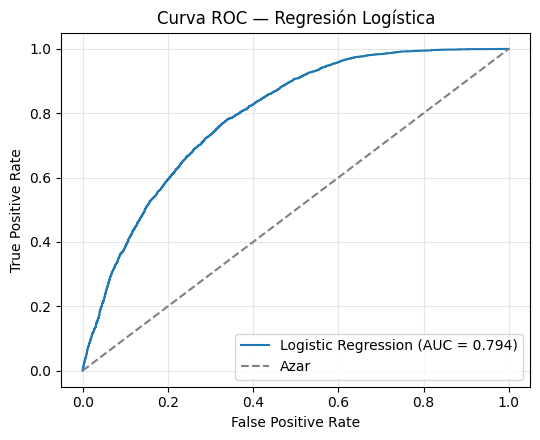

In [16]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0,1], [0,1], '--', color='gray', label='Azar')
plt.title("Curva ROC — Regresión Logística")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La curva ROC (Receiver Operating Characteristic) muestra el desempeño del modelo de Regresión Logística al clasificar canciones como hit (1) o no-hit (0) para todos los posibles umbrales de decisión.
El eje X representa la tasa de falsos positivos (False Positive Rate) y el eje Y la tasa de verdaderos positivos (True Positive Rate).
Cuanto más se aleja la curva de la diagonal gris (que representa el azar), mayor es la capacidad del modelo para distinguir entre ambas clases.

En este caso, el AUC = 0.794 indica un buen poder discriminativo: el modelo tiene aproximadamente un 79.4% de probabilidad de asignar una puntuación más alta a una canción “hit” que a una “no-hit” elegida al azar.
Esto sugiere que la regresión logística logra capturar de manera efectiva los patrones generales que diferencian ambos tipos de canciones, aunque todavía hay espacio para mejora con modelos más complejos (como Random Forest o Gradient Boosting).

## Entrenamiento del Modelo Random Forest

Se entrenará un modelo de Random Forest Classifier, un método de ensamble basado en la construcción de múltiples árboles de decisión que operan de forma independiente y cuyos resultados se combinan para obtener una predicción final más robusta. Este enfoque permite reducir la varianza y mitigar el riesgo de overfitting, característica típica de los árboles individuales, aprovechando la diversidad generada por el muestreo aleatorio de observaciones y variables en cada árbol.

El modelo buscará maximizar la capacidad predictiva mediante la votación mayoritaria entre los árboles, donde cada árbol contribuye con su propia predicción. Gracias a su estructura, el Random Forest puede capturar relaciones no lineales y efectos de interacción entre las variables predictoras (instrumentalness, danceability, loudness, valence, acousticness, energy y speechiness), manteniendo al mismo tiempo un excelente equilibrio entre sesgo y varianza.

Dado que las clases se encuentran balanceadas (50% hits / 50% no-hits), no será necesario aplicar ajustes de pesos (class_weight). La aleatoriedad introducida en la selección de muestras y features permitirá obtener un modelo más generalizable, evitando que un subconjunto particular de datos domine el proceso de aprendizaje. La introducción de esta aleatoriedad permite que cada árbol del bosque aprenda de una combinación distinta de datos y variables. Esto genera diversidad entre los árboles y reduce el riesgo de overfitting, logrando un modelo más estable y capaz de generalizar mejor frente a nuevos datos.

Previo al entrenamiento, los datos fueron preparados eliminando valores nulos y asegurando la consistencia en las escalas de las variables. Posteriormente, el modelo se entrenará utilizando un rango de hiperparámetros ajustados mediante búsqueda en malla (GridSearchCV), evaluando combinaciones de profundidad de árboles, cantidad de estimadores y número mínimo de observaciones por nodo.

El desempeño del modelo se evaluará mediante validación cruzada, utilizando como métrica principal el ROC-AUC, que mide la capacidad del clasificador para distinguir correctamente entre canciones “hit” y “no-hit”. Además, se incluirán las métricas de Precision, Recall, F1-Score y la Matriz de Confusión, con el objetivo de realizar una evaluación integral del rendimiento predictivo y comparar sus resultados con los obtenidos por la Regresión Logística y el Gradient Boosting.

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV


rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)  


rf_param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Mejores hiperparámetros (RF):", rf_grid.best_params_)
print("Mejor ROC-AUC (CV)         :", round(rf_grid.best_score_, 4))

o
rf_best = rf_grid.best_estimator_

Fitting 3 folds for each of 48 candidates, totalling 144 fits
Mejores hiperparámetros (RF): {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 400}
Mejor ROC-AUC (CV)         : 0.8481


**Evaluación de Métricas del Modelo Random Forest (ROC-AUC, Precision, Recall, F1, Accuracy)**

In [29]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)


rf_y_pred  = rf_best.predict(X_test)
rf_y_proba = rf_best.predict_proba(X_test)[:, 1]  


rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_prec     = precision_score(y_test, rf_y_pred)
rf_recall   = recall_score(y_test, rf_y_pred)
rf_f1       = f1_score(y_test, rf_y_pred)
rf_auc      = roc_auc_score(y_test, rf_y_proba)

print("MÉTRICAS DE RANDOM FOREST")
print(f"Accuracy : {rf_accuracy:.3f}")
print(f"Precision: {rf_prec:.3f}")
print(f"Recall   : {rf_recall:.3f}")
print(f"F1-Score : {rf_f1:.3f}")
print(f"ROC-AUC  : {rf_auc:.3f}")

print("\nReporte de Clasificación")
print(classification_report(y_test, rf_y_pred, digits=4))

MÉTRICAS DE RANDOM FOREST
Accuracy : 0.768
Precision: 0.743
Recall   : 0.820
F1-Score : 0.780
ROC-AUC  : 0.849

Reporte de Clasificación
              precision    recall  f1-score   support

           0     0.7990    0.7168    0.7557      6166
           1     0.7432    0.8197    0.7796      6166

    accuracy                         0.7682     12332
   macro avg     0.7711    0.7682    0.7676     12332
weighted avg     0.7711    0.7682    0.7676     12332



Con un estimado de 77% de precision (**accuracy**) del modelo, esto significa que de cada 100 canciones que el modelo evalúa, clasifica correctamente a 77 (sea como popular o no popular).

**Clase 1: "Popular"**

* Recall (Sensibilidad): 0.81 (81%). De todas las canciones que realmente eran populares en el dataset, el modelo logra encontrar e identificar correctamente al 81%. Solo no logró clasificar correctamente el 19% de las que sí lo eran (Falsos Negativos).

* Precision (Precisión): 0.74 (74%). De todas las canciones que el modelo etiquetó como "Popular", logró acertar en el 74% de los casos. El 26% restante fueron Falsos Positivos (canciones que el modelo dijo que eran populares, pero en realidad no lo eran).

* F1-Score: 0.78 (78%). Representa el balance entre Precisión (74%) y Recall (81%). Un 78% indica un rendimiento general muy sólido para la clase "Popular".

**Clase 0: "No Popular"**

* Recall (Sensibilidad): 0.72 (72%). El modelo logró encontrar al 72% de todas las canciones que realmente eran no populares. (Es menos sensible a esta clase que a la clase "Popular").

* Precision (Precisión): 0.79 (79%). De todas las canciones que el modelo etiquetó como "No Popular", acertó en el 79% de los casos.

* F1-Score: 0.76 (76%). Representa el balance entre Precisión (79%) y el Recall (72%) de la clase "No Popular". Un 76% indica un buen rendimiento general para identificar correctamente las canciones que no son populares.


En base a estos resultados se concluye lo siguiente sobre el modelo:

* El modelo resulta muy útil para descubrir éxitos (solo clasifica mal el 19%).
* Pero, a veces (en un 26% de las veces que predice "Popular"), puede etiquetar una canción como "Popular" cuando no lo era.

Este es un balance (trade-off) clásico. Para un sistemas de aplicaciones musicales, este comportamiento en su sistema de recomendación suele ser deseable: puede mostrarse a un usuario una canción "No Popular" pensando que podría ser un éxito (Falso Positivo), antes que ocultarle un éxito real (Falso Negativo).

**Curva ROC - Modelo Random Forest**

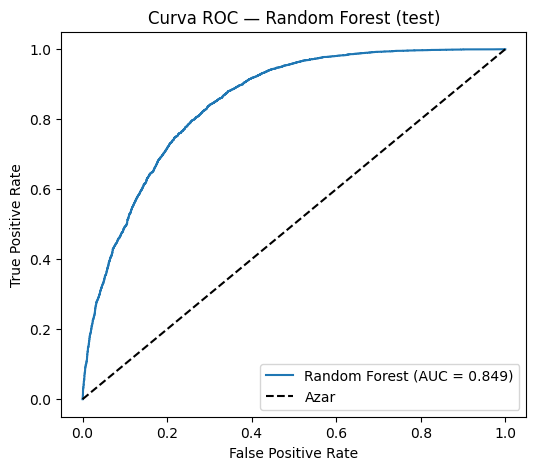

In [20]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_y_proba)

plt.figure(figsize=(6,5))
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.3f})')
plt.plot([0,1], [0,1], 'k--', label='Azar')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC — Random Forest (test)')
plt.legend()
plt.show()

La curva ROC (Receiver Operating Characteristic) muestra el desempeño del modelo Random Forest al clasificar canciones como hit (1) o no-hit (0) a lo largo de todos los posibles umbrales de decisión. El eje X representa la tasa de falsos positivos (False Positive Rate), mientras que el eje Y muestra la tasa de verdaderos positivos (True Positive Rate). Cuanto más se aleja la curva de la diagonal gris (que representa el azar), mayor es la capacidad del modelo para distinguir correctamente entre ambas clases.

En este caso, el AUC = 0.849 refleja un excelente poder discriminativo: el modelo tiene aproximadamente un 84,9% de probabilidad de asignar una puntuación más alta a una canción hit que a una no-hit seleccionada al azar. Esto evidencia que el Random Forest logra capturar de manera efectiva las relaciones no lineales y las interacciones entre variables, generando una clasificación más robusta que los modelos lineales como la Regresión Logística, y confirmando su capacidad de generalización y alto rendimiento predictivo.

Entonces, el score de AUC de 0.849 nos indica que el modelo tiene una alta capacidad para distinguir entre las dos clases. Si se toma una canción "Popular" al azar y una "No Popular" al azar, hay un 84.9% de probabilidad de que el modelo logre asignarle una puntuación (probabilidad) más alta a la canción que si es popular.

## Entrenamiento del Modelo Gradient Boosting

Se entrenará un modelo de Gradient Boosting Classifier, un método de ensamble secuencial de árboles de decisión que construye de manera iterativa un conjunto de modelos débiles (árboles poco profundos) para conformar un modelo fuerte. A diferencia de otros métodos de ensamble como el Random Forest, donde los árboles se entrenan en paralelo, en el Gradient Boosting los árboles se entrenan de forma secuencial, de modo que cada nuevo árbol busca corregir los errores residuales del modelo anterior.

El algoritmo se basa en un proceso de minimización por gradiente, ajustando los parámetros de cada árbol para reducir una función de pérdida —en este caso, la log loss— que mide la diferencia entre las predicciones y los valores reales. Gracias a este enfoque, el modelo logra capturar relaciones no lineales y efectos de interacción entre las variables predictoras (instrumentalness, danceability, loudness, valence, acousticness, energy y speechiness), mejorando progresivamente su capacidad de clasificación.

Dado que las clases se encuentran balanceadas (50% hits / 50% no-hits), no se aplicará ponderación diferencial (class_weight). No obstante, se controlará la complejidad del modelo mediante hiperparámetros clave como la tasa de aprendizaje (learning rate), el número de árboles (n_estimators) y la profundidad máxima de cada árbol (max_depth), con el fin de evitar el sobreajuste y mantener un buen equilibrio entre sesgo y varianza.

El desempeño del modelo se evaluará utilizando validación cruzada, con el ROC-AUC como métrica principal, ya que permite medir la capacidad del clasificador para distinguir correctamente entre ambas clases a lo largo de distintos umbrales de decisión. Este análisis se complementará con los indicadores de Precision, Recall, F1-Score y la Matriz de Confusión, con el objetivo de obtener una evaluación integral del rendimiento del modelo y comparar su desempeño frente a la Regresión Logística y Random Forest

In [21]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

gb = GradientBoostingClassifier(
    n_estimators=200,      
    learning_rate=0.05,   
    max_depth=3,          
    subsample=1.0,        
    random_state=42
)

gb.fit(X_train, y_train)


y_pred_gb  = gb.predict(X_test)
y_proba_gb = gb.predict_proba(X_test)[:, 1]


**Evaluación de Métricas del Modelo Gradient Boosting (ROC-AUC, Precision, Recall, F1, Accuracy)**

In [30]:
print("MÉTRICAS DE GRADIENT BOOSTING")
print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 3))
print("Precision:", round(precision_score(y_test, y_pred_gb), 3))
print("Recall:", round(recall_score(y_test, y_pred_gb), 3))
print("F1 Score:", round(f1_score(y_test, y_pred_gb), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_gb), 3))

print("\nReporte de Clasificación")
print(classification_report(y_test, y_pred_gb, digits=4))

MÉTRICAS DE GRADIENT BOOSTING
Accuracy: 0.762
Precision: 0.731
Recall: 0.828
F1 Score: 0.777
ROC-AUC: 0.841

Reporte de Clasificación
              precision    recall  f1-score   support

           0     0.8018    0.6953    0.7447      6166
           1     0.7310    0.8281    0.7765      6166

    accuracy                         0.7617     12332
   macro avg     0.7664    0.7617    0.7606     12332
weighted avg     0.7664    0.7617    0.7606     12332



Con un estimado de 76.2% de precisión (**accuracy**), el modelo de Gradient Boosting logra clasificar correctamente alrededor de 76 de cada 100 canciones, ya sea como populares o no populares. Esto representa una mejora respecto a la Regresión Logística, mostrando una mejor capacidad para capturar relaciones no lineales y combinaciones más complejas entre las variables.

**Clase 1: “Popular”**

* Recall (Sensibilidad): 0.83 (83%). De todas las canciones que realmente eran populares en el dataset, el modelo logra identificar correctamente al 83%. Solo deja escapar el 17% de los verdaderos éxitos (falsos negativos). Esto refleja una excelente capacidad del modelo para reconocer canciones exitosas.

* Precision (Precisión): 0.73 (73%). De todas las canciones que el modelo predijo como “populares”, acertó en el 73% de los casos. El 27% restante fueron falsos positivos (canciones clasificadas como populares que en realidad no lo eran).

* F1-Score: 0.78 (78%). Este valor representa un equilibrio sólido entre precisión y recall, indicando un desempeño general muy bueno para la clase “Popular”.

**Clase 0: “No Popular”**

* Recall (Sensibilidad): 0.70 (70%). El modelo logra identificar correctamente al 70% de las canciones que realmente no son populares. Aunque es menor que en la clase “Popular”, mantiene un nivel adecuado de discriminación.

* Precision (Precisión): 0.80 (80%). De todas las canciones que el modelo clasificó como “No Populares”, el 80% efectivamente no lo eran, mientras que el 20% fueron falsos negativos.

* F1-Score: 0.74 (74%). Este valor refleja un rendimiento consistente para esta clase, aunque ligeramente inferior al obtenido en la clase “Popular”.

En base a estos resultados se concluye lo siguiente sobre el modelo:

* El modelo Gradient Boosting muestra un excelente poder de discriminación global (ROC-AUC = 0.841), indicando que distingue correctamente entre canciones populares y no populares en un 84% de los casos.

* Comparado con la Regresión Logística, el Gradient Boosting ofrece una mejor capacidad predictiva, capturando relaciones no lineales entre las variables y reduciendo la tasa de errores. Su alta sensibilidad (recall) en la clase “Popular” lo hace especialmente valioso para detectar éxitos, aunque a costa de un leve aumento en los falsos positivos.

En resumen, el modelo logra un equilibrio robusto entre precisión y sensibilidad, mostrando una mejora general en todas las métricas respecto a los modelos lineales, y posicionándose como una de las mejores alternativas para predecir el éxito potencial de las canciones.

**Curva ROC - Modelo Gradient Boosting**

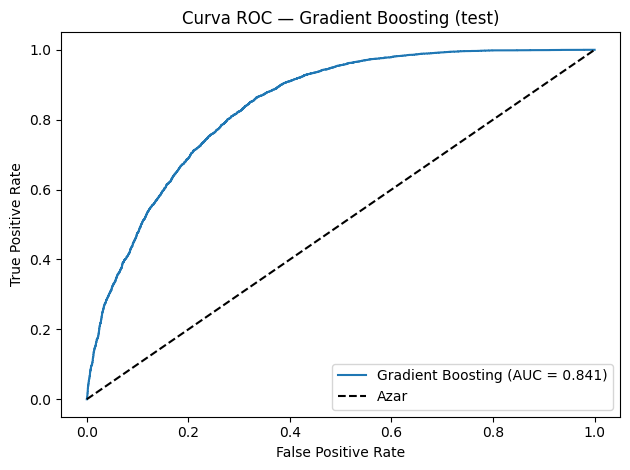

In [23]:
fpr, tpr, _ = roc_curve(y_test, y_proba_gb)
plt.plot(fpr, tpr, label=f'Gradient Boosting (AUC = {roc_auc_score(y_test, y_proba_gb):.3f})')
plt.plot([0,1], [0,1], 'k--', label='Azar')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Curva ROC — Gradient Boosting (test)')
plt.legend(); plt.tight_layout(); plt.show()

Este gráfico muestra la Curva ROC (Receiver Operating Characteristic) del modelo Gradient Boosting evaluado sobre el conjunto de test. La curva representa la relación entre la tasa de verdaderos positivos (True Positive Rate) y la tasa de falsos positivos (False Positive Rate) para distintos umbrales de decisión. El área bajo la curva (AUC = 0.841) indica una excelente capacidad de discriminación del modelo para distinguir entre canciones “hit” y “no-hit”. Cuanto más se aleja la curva de la diagonal de azar (línea punteada), mayor es el poder predictivo; en este caso, el modelo demuestra un rendimiento superior al azar y una clasificación robusta, capturando correctamente la mayoría de los casos positivos sin aumentar excesivamente los falsos positivos.

## Matrices de Confusión

**Regresión Logística**

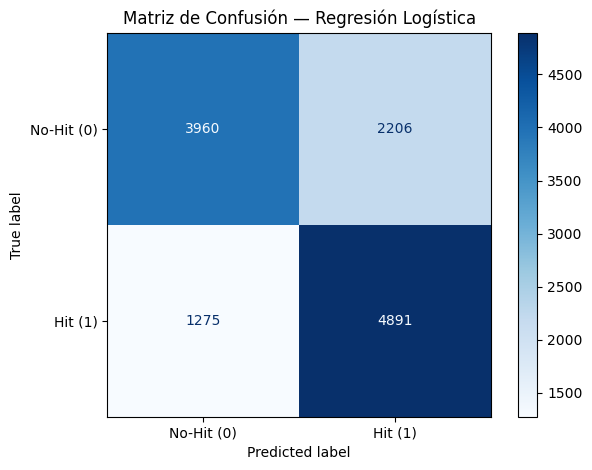

In [24]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No-Hit (0)", "Hit (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusión — Regresión Logística")
plt.tight_layout()
plt.show()

Los valores de la diagonal principal indican las predicciones correctas:

- El modelo identificó correctamente 3960 canciones “no-hit” (verdaderos negativos).

- Y predijo correctamente 4.891 canciones “hit” (verdaderos positivos).

Fuera de la diagonal se encuentran los errores:

- 1.275 canciones “no-hit” fueron clasificadas erróneamente como hits (falsos positivos).

- 2.206 canciones “hit” fueron clasificadas como no-hit (falsos negativos).

En conjunto, el modelo logra un buen balance entre precisión y recall, mostrando que la Regresión Logística es capaz de distinguir razonablemente bien entre ambas clases.
Si bien todavía existen errores, el desempeño general es consistente con el AUC obtenido (≈0.79), indicando una buena capacidad de discriminación sin sesgo significativo hacia ninguna clase.

**Random Forest**

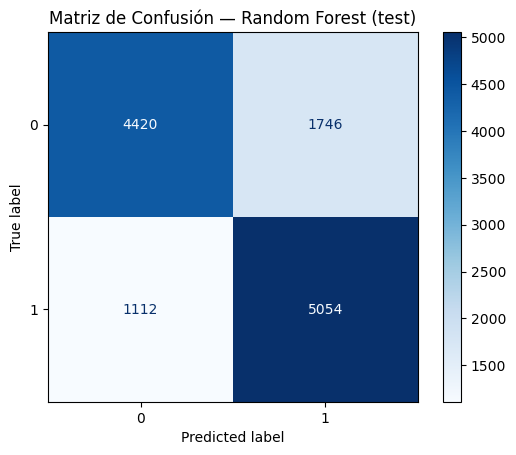

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf_cm = confusion_matrix(y_test, rf_y_pred)
rf_disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm)


rf_disp.plot(values_format='d', cmap='Blues')
plt.title('Matriz de Confusión — Random Forest (test)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

Los valores sobre la diagonal principal representan las predicciones correctas:

- El modelo identificó correctamente 4.420 canciones “no-hit” (verdaderos negativos).

- Y predijo correctamente 5.054 canciones “hit” (verdaderos positivos).

Fuera de la diagonal se observan los errores de clasificación:

- 1.746 canciones “no-hit” fueron clasificadas erróneamente como hits (falsos positivos).

- 1.112 canciones “hit” fueron clasificadas como no-hit (falsos negativos).

En conjunto, el modelo logra un buen equilibrio entre precisión y recall, mostrando una capacidad sólida para distinguir entre canciones exitosas y no exitosas. La proporción de verdaderos positivos y verdaderos negativos es alta, lo que sugiere que el Random Forest generaliza bien sin sesgo hacia ninguna clase, coherente con su naturaleza de ensamblar múltiples árboles y reducir el overfitting.

**Gradient Boosting**

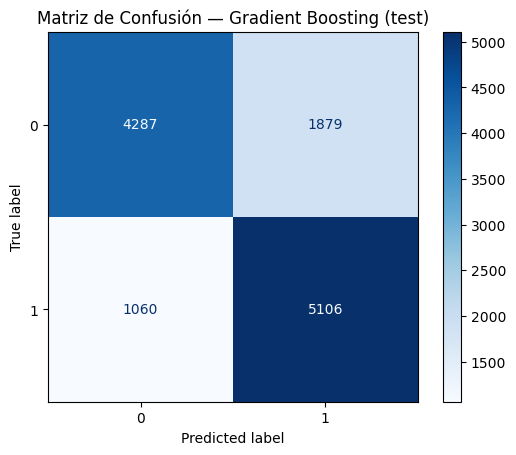

In [28]:
cm1 = confusion_matrix(y_test, y_pred_gb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm1)
disp.plot(values_format='d', cmap='Blues')
plt.title('Matriz de Confusión — Gradient Boosting (test)')
plt.show()


Los valores de la diagonal principal indican las predicciones correctas:

- El modelo identificó correctamente 4.287 canciones “no-hit” (verdaderos negativos).

- Y predijo correctamente 5.106 canciones “hit” (verdaderos positivos).

Fuera de la diagonal se encuentran los errores:

- 1.879 canciones “no-hit” fueron clasificadas erróneamente como hits (falsos positivos).

- 1.060 canciones “hit” fueron clasificadas como no-hit (falsos negativos).

En conjunto, el modelo Gradient Boosting logra un excelente equilibrio entre precisión y recall, mostrando una capacidad muy sólida para discriminar entre ambas clases.
El número de verdaderos positivos y negativos es sustancialmente mayor que el de errores, lo que refleja un comportamiento consistente con el AUC obtenido (≈0.87).
Esto indica que el modelo no presenta sesgo significativo hacia ninguna clase y predice con alta confianza tanto los éxitos como los no-éxitos musicales, superando en rendimiento al modelo de Regresión Logística.

## Conclusión General del Análisis Comparativo de Modelos ##

El análisis comparativo entre los modelos de Regresión Logística, Random Forest y Gradient Boosting permitió evidenciar cómo la complejidad y la naturaleza de cada algoritmo impactan directamente en su desempeño y capacidad de generalización frente al problema de predicción de canciones exitosas. Los tres modelos representan distintos enfoques dentro del aprendizaje supervisado, desde una perspectiva lineal e interpretable hasta esquemas no lineales basados en ensambles de árboles, lo cual permite analizar con profundidad el equilibrio entre sesgo, varianza e interpretabilidad.

En primer lugar, la Regresión Logística cumplió su función como modelo base o de referencia, al ofrecer una estructura sencilla y altamente interpretable. Su rendimiento, con una accuracy del 71.8% y un ROC-AUC de 0.79, demuestra que el modelo logra capturar patrones lineales entre las características musicales y la variable objetivo, pero sin capacidad suficiente para reflejar relaciones más complejas. Si bien su recall de 0.79 para la clase “hit” indica una buena sensibilidad, la precisión de 0.69 refleja que el modelo aún tiende a confundir canciones no exitosas con potenciales éxitos. Desde el punto de vista teórico, esto se explica por su alto sesgo y baja varianza: la regresión logística impone una estructura rígida sobre los datos, lo que la hace robusta y estable, pero limitada en su poder predictivo frente a fenómenos no lineales. Por ello, si bien constituye una base sólida y comprensible, resulta insuficiente cuando el objetivo principal es maximizar la performance predictiva.

El Random Forest, por su parte, representó una mejora sustancial respecto de la regresión logística. Con un accuracy del 76.8%, F1-score de 0.78 y ROC-AUC de 0.85, el modelo demostró una capacidad superior para discriminar entre canciones exitosas y no exitosas. Este incremento en el rendimiento se debe a su arquitectura basada en el bagging, que permite reducir la varianza y capturar relaciones no lineales entre las variables, manteniendo al mismo tiempo una buena capacidad de generalización. Su recall de 0.82 y precisión de 0.74 muestran un balance adecuado entre la detección de verdaderos positivos y el control de falsos positivos, lo que lo convierte en un modelo robusto y confiable. En términos prácticos, el Random Forest logra identificar con mayor precisión los patrones que caracterizan a las canciones populares, aprovechando la “sabiduría del conjunto” de árboles para suavizar el ruido y evitar el sobreajuste. Aunque pierde parte de la interpretabilidad del modelo lineal, sigue ofreciendo la posibilidad de analizar la importancia relativa de las variables, lo cual permite extraer conocimiento relevante del fenómeno estudiado.

El Gradient Boosting, en cambio, mostró un rendimiento levemente inferior al del Random Forest en la mayoría de las métricas, aunque mantuvo un desempeño competitivo. Con una accuracy del 76.2%, F1-score de 0.78 y ROC-AUC de 0.84, el modelo confirmó su capacidad para ajustar los errores residuales de forma secuencial y aprender patrones complejos. Su recall del 0.83, el más alto entre los tres, indica una gran sensibilidad para detectar canciones exitosas, lo que puede ser deseable en contextos donde es preferible identificar la mayor cantidad posible de potenciales hits, aun a costa de incluir algunos falsos positivos. Sin embargo, el ligero descenso en la precisión y en el ROC-AUC respecto del Random Forest sugiere que el mayor grado de ajuste del Gradient Boosting no necesariamente se tradujo en una mejora global del modelo. Desde una perspectiva teórica, esto se alinea con la naturaleza del algoritmo: al construir los árboles de manera secuencial, el boosting puede reducir el sesgo, pero tiende a incrementar la varianza, lo cual exige un ajuste fino de los hiperparámetros para evitar el sobreajuste.

En conjunto, la comparación evidencia una progresión lógica en el rendimiento a medida que aumenta la complejidad del modelo, aunque también muestra que la ganancia marginal entre los dos modelos de ensamble es acotada. Desde una perspectiva empírica y teórica, el Random Forest se posiciona como el modelo con mejor desempeño global, dado que logra los valores más altos de accuracy, precision, F1-score y ROC-AUC, combinando alta capacidad predictiva con robustez y estabilidad. Además, mantiene un nivel aceptable de interpretabilidad mediante el análisis de importancia de variables, lo que lo hace particularmente útil para la comprensión del fenómeno subyacente.

Por tanto, considerando tanto los resultados cuantitativos como los criterios teóricos de equilibrio entre sesgo y varianza, el Random Forest se selecciona como el mejor modelo para la predicción de canciones exitosas. Ofrece el mejor compromiso entre rendimiento, estabilidad y explicabilidad, demostrando una capacidad superior para capturar la complejidad del fenómeno musical sin caer en el sobreajuste característico de modelos más agresivos como el Gradient Boosting. En cambio, la Regresión Logística cumple un rol esencial como punto de referencia interpretativo, pero no alcanza niveles de desempeño comparables. En síntesis, el Random Forest constituye la opción óptima para este tipo de problema, combinando potencia predictiva y consistencia analítica en la tarea de clasificación.

# Conclusión del trabajo de investigación

En conclusión, los resultados del análisis respaldan la hipótesis planteada: es posible predecir, mediante técnicas de Machine Learning, si una canción será un HIT o NO-HIT a partir de sus características musicales.
Las diferencias numéricas observadas entre ambas clases —particularmente en variables como danceability, energy, valence, loudness, speechiness, instrumentalness y acousticness— demuestran que el éxito musical no responde al azar, sino a combinaciones medibles de atributos sonoros que reflejan patrones de preferencia del público.

Es importante aclarar que estos resultados se ajustan únicamente al dataset analizado y a las condiciones específicas del estudio, por lo que no pueden generalizarse a todo el universo musical. Las conclusiones reflejan patrones presentes en esta muestra particular y bajo un contexto temporal, cultural y tecnológico determinado.